# Dependence and Network Structure in the WTI Crude Oil Market

This project was undertaken in completion of COMP0047 Data Science, a required module in the MSc Computational Finance programme at University College London (UCL).

## Motivation

The group project used Pearson correlation to screen features for next-day West Texas Intermediate (WTI) crude oil log returns. This individual analysis asks how the picture changes when rank correlations and mutual information are used to compare features and map their relationships.

## Research Questions

1. **Feature dependence.** How do Pearson, Spearman, Kendall and normalised mutual information rank features by their association with next-day WTI returns?
2. **Network structure.** What relationships among features emerge in minimum spanning tree (MST), planar maximally filtered graph (PMFG) and triangulated maximally filtered graph (TMFG) representations?
3. **Directional dependence.** What do pairwise Granger causality tests and transfer entropy suggest about directional relationships between the features and same-day WTI returns?

## Data

The analysis uses 1,895 daily observations and 76 features from 31 January 2017 to 3 March 2026. The features cover market prices and volatility, oil inventories, geopolitical indicators and survey data.

The group coursework supplied the starting dataset and baseline diagnostics. The extended dependence, network and directional analyses are individual work.

## Notebook Setup

In [1]:
# !pip install -U matplotlib
# !pip install matplotlib==3.1.0
# %matplotlib inline

In [2]:
import warnings

import numpy as np
import itertools
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
# from matplotlib import colormaps
import seaborn as sns

import networkx as nx
import networkx.algorithms.community as nx_comm

from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.tsa.stattools import adfuller

In [3]:
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

## Baseline Analysis

### Load the Data

In [4]:
df = pd.read_parquet('../Data/sanity_data.parquet')
TARGET = 'Target'
print(df.shape)
df.head()

(1895, 80)


,Date,Target,WTI_Close,Brent_Close,WTI_Log_Returns,Brent_Log_Return,WTI_Ret_Lag1,WTI_Ret_Lag2,WTI_Ret_Lag3,WTI_Ret_Lag4,WTI_Ret_Lag5,WTI_Ret_Lag6,WTI_Ret_Lag7,WTI_Ret_Lag8,WTI_Ret_Lag9,WTI_Ret_Lag10,WTI_Ret_Vol_5D,WTI_Ret_Vol_10D,WTI_Ret_Vol_20D,WTI_Ret_Vol_60D,WTI_Spot_Momentum_5D,WTI_Spot_Momentum_20D,Brent_WTI_Spread,Brent_WTI_Spread_Chg,SP500_Close,VIX_Close,DXY_Close,SP500_Log_Return,VIX_Log_Return,DXY_Log_Return,Inv_WoW,Inv_WoW_Z4,Inv_WoW_Z13,AvgTone_DailyAvg,GoldsteinScale_DailyAvg,OVX_Log_Return,SPR_WoW,DaysSupply_WoW,Total_Stocks_WoW,Global_Tone_5D_Chg,Global_Goldstein_5D_Chg,Mentions_Volume_Surge,OPEC_Tension_Index,OPEC_Tension_5D_Chg,SAU_Goldstein_5D_Chg,SAU_Tone_5D_Chg,RUS_Goldstein_5D_Chg,RUS_Tone_5D_Chg,IRQ_Goldstein_5D_Chg,IRQ_Tone_5D_Chg,USA_Tone_5D_Chg,CHN_Tone_5D_Chg,FedAll_Qcexp,FedAll_Qolk,FedAll_Quncr,FedAll_Qemp,FedAll_Qsdtm,FedAll_Qwgs,FedAll_Qbac,FedEP_Qcexp,FedEP_Qolk,FedEP_Quncr,FedEP_Qemp,FedOG_Qolk,FedOG_Quncr,FedOG_Qcexp,FedAll_Qcexp_5D_Chg,FedAll_Qolk_5D_Chg,FedAll_Quncr_5D_Chg,FedAll_Qemp_5D_Chg,FedAll_Qsdtm_5D_Chg,FedAll_Qwgs_5D_Chg,FedAll_Qbac_5D_Chg,FedEP_Qcexp_5D_Chg,FedEP_Qolk_5D_Chg,FedEP_Quncr_5D_Chg,FedEP_Qemp_5D_Chg,FedOG_Qolk_5D_Chg,FedOG_Quncr_5D_Chg,FedOG_Qcexp_5D_Chg
0,2017-01-31,0.020059,52.810001,55.700001,0.003414,0.008474,-0.010208,0.007931,-0.008119,0.008119,0.006276,0.020234,0.005661,-0.027039,0.002098,0.002294,0.008808,0.012995,0.016810,0.024486,0.113747,-2.312246,2.889999,0.290001,2278.870117,11.99,99.510002,-0.000890,0.009217,-0.009203,0.0,-0.5,-0.463223,-4.344139,-5.672047,0.012526,0.0,0.0,0.0,-0.710977,0.285544,0.275650,-5.743256,0.108058,-1.325778,-1.235012,-0.039783,-1.313073,2.111441,-0.178198,-0.762436,-1.043777,30.043333,49.305556,15.9,5.975556,4.36,14.908889,41.252222,28.75,47.544444,19.7,-4.821111,52.111111,12.0,31.797778,0.303333,-0.894444,0.0,0.295556,0.42,0.528889,0.132222,-0.35,-2.255556,0.0,-0.381111,0.311111,0.0,0.917778
1,2017-02-01,-0.000928,53.880001,55.660000,0.020059,-0.000718,0.003414,-0.010208,0.007931,-0.008119,0.008119,0.006276,0.020234,0.005661,-0.027039,0.002098,0.012378,0.014359,0.017425,0.024399,1.316286,0.204576,1.779999,-1.110001,2279.550049,11.81,99.639999,0.000298,-0.015126,0.001306,0.0,-0.5,-0.463223,-4.441852,-5.666695,-0.021943,0.0,0.0,0.0,-0.245619,0.263032,0.127656,-5.823242,0.038715,-0.811087,-1.171819,-0.034494,-0.601464,1.589048,-0.366720,-0.833517,-1.702047,30.086667,49.177778,15.9,6.017778,4.42,14.984444,41.271111,28.70,47.222222,19.7,-4.875556,52.155556,12.0,31.928889,0.303333,-0.894444,0.0,0.295556,0.42,0.528889,0.132222,-0.35,-2.255556,0.0,-0.381111,0.311111,0.0,0.917778
2,2017-02-03,-0.015350,53.830002,56.810001,-0.000928,0.020451,0.020059,0.003414,-0.010208,0.007931,-0.008119,0.008119,0.006276,0.020234,0.005661,-0.027039,0.011178,0.010109,0.017425,0.024317,2.047397,0.204767,2.980000,1.200001,2297.419922,10.97,99.870003,0.007809,-0.073782,0.002306,13829.0,1.5,2.952069,-4.538870,-5.258885,-0.044529,-1.0,1.4,13828.0,-0.344868,0.150052,0.078608,-5.517127,0.185300,-1.104385,-1.050830,0.019455,-0.736919,0.746705,0.332462,-0.366443,-0.975343,30.173333,48.922222,15.9,6.102222,4.54,15.135556,41.308889,28.60,46.577778,19.7,-4.984444,52.244444,12.0,32.191111,0.303333,-0.894444,0.0,0.295556,0.42,0.528889,0.132222,-0.35,-2.255556,0.0,-0.381111,0.311111,0.0,0.917778
3,2017-02-06,-0.015973,53.009998,55.720001,-0.015350,-0.019373,-0.000928,0.020059,0.003414,-0.010208,0.007931,-0.008119,0.008119,0.006276,0.020234,0.005661,0.013719,0.012016,0.016717,0.024390,-0.300921,1.299439,2.710003,-0.269997,2292.560059,11.37,99.910004,-0.002118,0.035814,0.000400,0.0,-0.5,-0.435958,-3.855612,-5.626490,0.043848,0.0,0.0,0.0,0.325791,-0.086653,-0.179242,-5.653107,-0.185244,-0.684720,-0.149605,0.516559,0.563570,-1.102889,-0.172363,0.148806,-1.234098,30.303333,48.538889,15.9,6.228889,4.72,15.362222,41.365556,28.45,45.611111,19.7,-5.147778,52.377778,12.0,32.584444,0.303333,-0.894444,0.0,0.295556,0.42,0.528889,0.132222,-0.35,-2.255556,0.0,-0.381111,0.311111,0.0,0.91

### Baseline Diagnostics

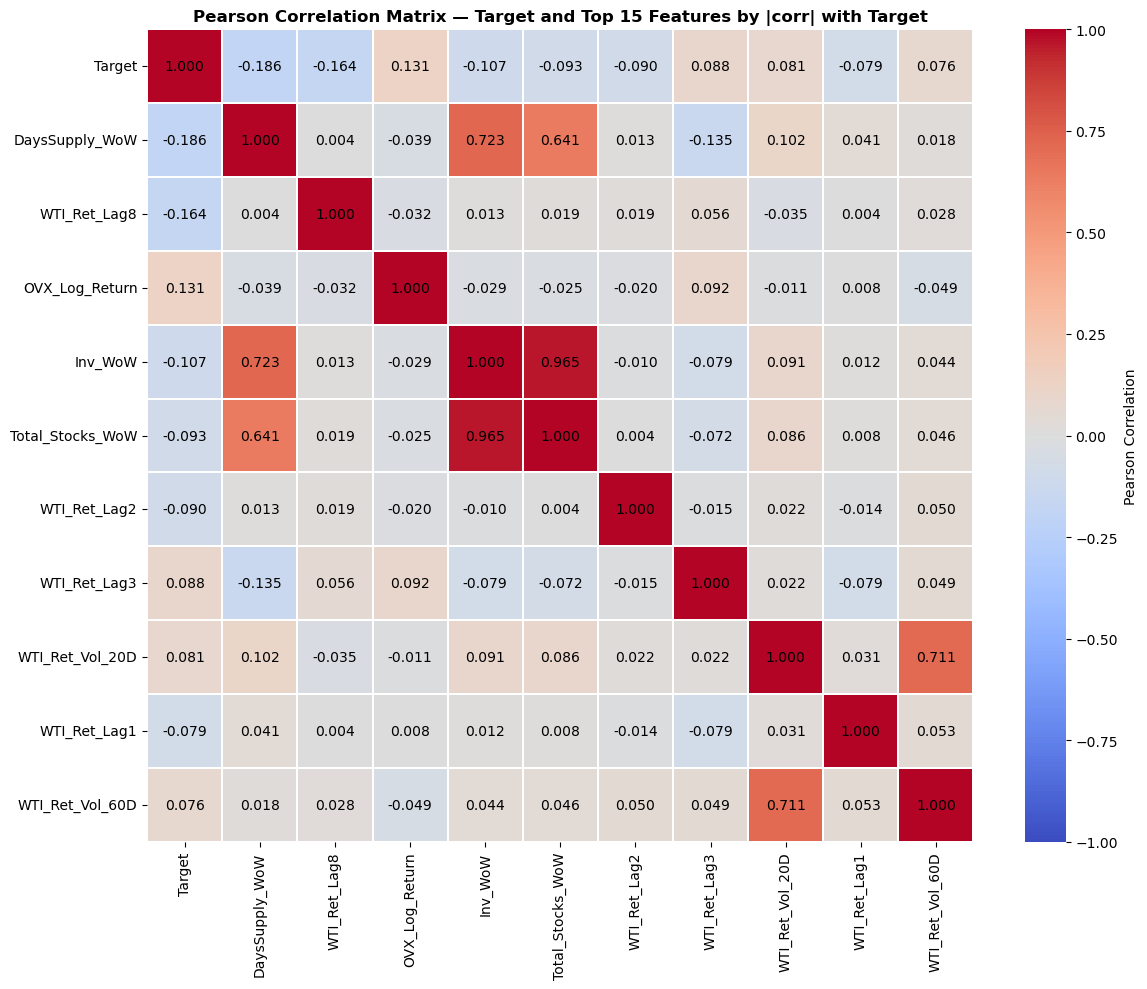

In [5]:
''' From Group Project Code'''

NON_FEATURE_COLS = ['Date', 'Target', 'WTI_Close', 'Brent_Close']
feature_cols = [c for c in df.columns if c not in NON_FEATURE_COLS]

n_feat = 10
top_n = (
    df[feature_cols + [TARGET]]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .abs()
    .sort_values(ascending=False)
    .head(n_feat)
    .index.tolist())

## Put Target first so it appears in first row/column
heatmap_cols = [TARGET] + top_n
corr_matrix = df[heatmap_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    ax=ax,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.3f',
    annot_kws={'size': 10, 'color': 'black'},
    linewidths=0.3,
    cbar_kws={'label': 'Pearson Correlation'}
)

ax.set_title('Pearson Correlation Matrix — Target and Top 15 Features by |corr| with Target', fontweight='bold')

plt.tight_layout()
# plt.savefig('../Figures/GroupPearsonCorr.pdf', bbox_inches='tight')
plt.show()

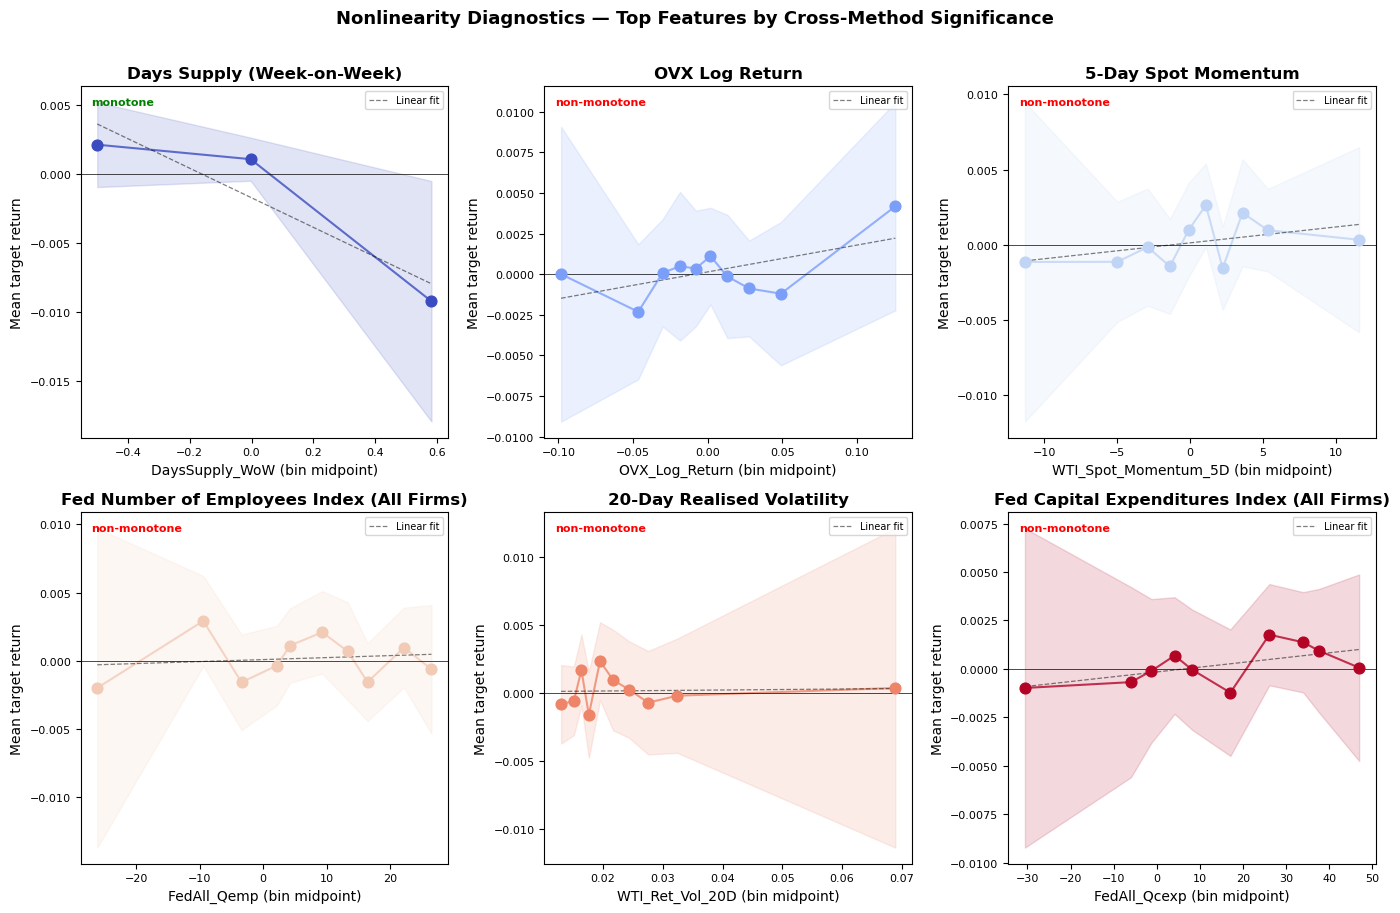

Nonlinearity summary:
  DaysSupply_WoW                      monotone
  OVX_Log_Return                      non-monotone
  WTI_Spot_Momentum_5D                non-monotone
  FedAll_Qemp                         non-monotone
  WTI_Ret_Vol_20D                     non-monotone
  FedAll_Qcexp                        non-monotone


In [6]:
'''From Group Project Code'''

diag_features = [
    ("DaysSupply_WoW",        "Days Supply (Week-on-Week)"),
    ("OVX_Log_Return",        "OVX Log Return"),
    ("WTI_Spot_Momentum_5D",  "5-Day Spot Momentum"),
    ("FedAll_Qemp",           "Fed Number of Employees Index (All Firms)"),
    ("WTI_Ret_Vol_20D",       "20-Day Realised Volatility"),
    ("FedAll_Qcexp",          "Fed Capital Expenditures Index (All Firms)"),
]
diag_features = [(f, l) for f, l in diag_features if f in df.columns]

cmap   = plt.cm.coolwarm
colors = [cmap(i / (len(diag_features) - 1)) for i in range(len(diag_features))]

ncols = 3
nrows = (len(diag_features) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.5 * nrows))
axes_flat = np.array(axes).flatten()

for ax, (feat, label), color in zip(axes_flat, diag_features, colors):
    sub = df[[feat, TARGET]].dropna().copy()
    try:
        sub["bin"] = pd.qcut(sub[feat], q=10, duplicates="drop")
    except Exception:
        sub["bin"] = pd.cut(sub[feat], bins=8, duplicates="drop")

    binned  = sub.groupby("bin", observed=False)[TARGET].agg(["mean", "sem"])
    bin_mids = sub.groupby("bin", observed=False)[feat].mean().values
    means   = binned["mean"].values
    sems    = binned["sem"].fillna(0).values

    ax.scatter(bin_mids, means, color=color, s=60, zorder=3)
    ax.plot(bin_mids, means, color=color, linewidth=1.5, alpha=0.8)
    ax.fill_between(bin_mids,
                    means - 1.96 * sems,
                    means + 1.96 * sems,
                    alpha=0.15, color=color)
    ax.axhline(0, color="black", linewidth=0.5)

    if len(bin_mids) > 2:
        p  = np.polyfit(bin_mids, means, 1)
        xr = np.linspace(bin_mids.min(), bin_mids.max(), 50)
        ax.plot(xr, np.polyval(p, xr), "k--", linewidth=0.9, alpha=0.5, label="Linear fit")
        ax.legend(fontsize=7)

    ax.set_title(label, fontweight="bold")
    ax.set_xlabel(f"{feat} (bin midpoint)")
    ax.set_ylabel("Mean target return")
    ax.tick_params(labelsize=8)

    diffs = np.diff(means)
    mono  = all(d >= 0 for d in diffs) or all(d <= 0 for d in diffs)
    ax.text(0.03, 0.97,
            "monotone" if mono else "non-monotone",
            transform=ax.transAxes,
            va="top", fontsize=8,
            color="green" if mono else "red",
            fontweight="bold")

for ax in axes_flat[len(diag_features):]:
    ax.set_visible(False)

plt.suptitle("Nonlinearity Diagnostics — Top Features by Cross-Method Significance",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig('../Figures/NonlinearityDiagnostic_TopFeatures.pdf', bbox_inches='tight')
plt.show()

print("Nonlinearity summary:")
for feat, label in diag_features:
    sub = df[[feat, TARGET]].dropna().copy()
    try:
        sub["bin"] = pd.qcut(sub[feat], q=10, duplicates="drop")
    except Exception:
        sub["bin"] = pd.cut(sub[feat], bins=8, duplicates="drop")
    means = sub.groupby("bin", observed=False)[TARGET].mean().values
    diffs = np.diff(means)
    mono  = all(d >= 0 for d in diffs) or all(d <= 0 for d in diffs)
    print(f"  {feat:<35} {'monotone' if mono else 'non-monotone'}")

## Individual Analysis

### Mutual Information

In [7]:
def entropy(x, bins=25):
    
    ## Estimate probability mass in each bin
    counts, _ = np.histogram(x, bins=bins)
    probs = counts / counts.sum()
    probs = probs[probs > 0]
    return -np.sum(probs * np.log(probs)) # Shannon entropy

In [8]:
def joint_entropy(x, y, bins=25):
    
    ## Same as before, but for joint distribution case
    counts, _, _ = np.histogram2d(x, y, bins=bins)
    probs = counts / counts.sum()
    probs = probs[probs > 0]
    return -np.sum(probs * np.log(probs))

In [9]:
def mutual_information(x, y, bins=25):
    
    ## I(X, Y) = H(X) + H(Y) - H(X, Y)
    return entropy(x, bins) + entropy(y, bins) - joint_entropy(x, y, bins)

In [10]:
def normalised_mutual_information(x, y, bins=25):

    ## Normalise MI to make it comparable across all feature pairs
    hx = entropy(x, bins)
    hy = entropy(y, bins)
    if hx == 0 or hy == 0:
        return 0.0
    mi = mutual_information(x, y, bins)
    return mi / np.sqrt(hx * hy)

In [11]:
def mi_matrix(df, cols, bins=25):

    n = len(cols)
    mat = np.ones((n, n)) # Diagonal always consists of ones

    for i in range(n):
        for j in range(i + 1, n):
            sub = df[[cols[i], cols[j]]].dropna()
            nmi = normalised_mutual_information(sub[cols[i]].values, sub[cols[j]].values, bins=bins)
            mat[i, j] = nmi
            mat[j, i] = nmi # Matrix is symmetric

    return pd.DataFrame(mat, index=cols, columns=cols)

In [12]:
def get_top_cols(df, feature_cols, target, n, method='pearson'):
    return [target] + (df[feature_cols + [target]].corr(method=method, numeric_only=True)[target]
           .drop(target).abs().sort_values(ascending=False).head(n).index.tolist())

In [13]:
n_obs = df[heatmap_cols].dropna().shape[0]
n_bins = int(np.ceil(np.log2(n_obs) + 1)) # Use Sturges' formula for bin size
print(f"Sturges' formula: n={n_obs}, bins={n_bins}")

## Compute matrices
n_feat = 10
pearson_cols = get_top_cols(df, feature_cols, TARGET, n_feat, 'pearson')
spearman_cols = get_top_cols(df, feature_cols, TARGET, n_feat, 'spearman')
kendall_cols = get_top_cols(df, feature_cols, TARGET, n_feat, 'kendall')

pearson_comp = df[pearson_cols].corr(method='pearson')
spearman_comp = df[spearman_cols].corr(method='spearman')
kendall_comp = df[kendall_cols].corr(method='kendall')

nmi_comp = mi_matrix(df, heatmap_cols, bins=n_bins)

Sturges' formula: n=1895, bins=12


In [14]:
def plot_matrix(mat, title, vmin, figname, figsize=(10, 8)):
    
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(mat, ax=ax, cmap='coolwarm', center=0, vmin=vmin, vmax=1, 
                annot=False, linewidths=0.3, cbar_kws={'label': title})
    
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j + 0.5, i + 0.5, f'{mat.iloc[i, j]:.3f}', ha='center', 
                    va='center', fontsize=8, color='black')
            
    ax.set_title(title, fontweight='bold')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    plt.tight_layout()
    plt.savefig(f'../Figures/{figname}.pdf', bbox_inches='tight')
    plt.show()

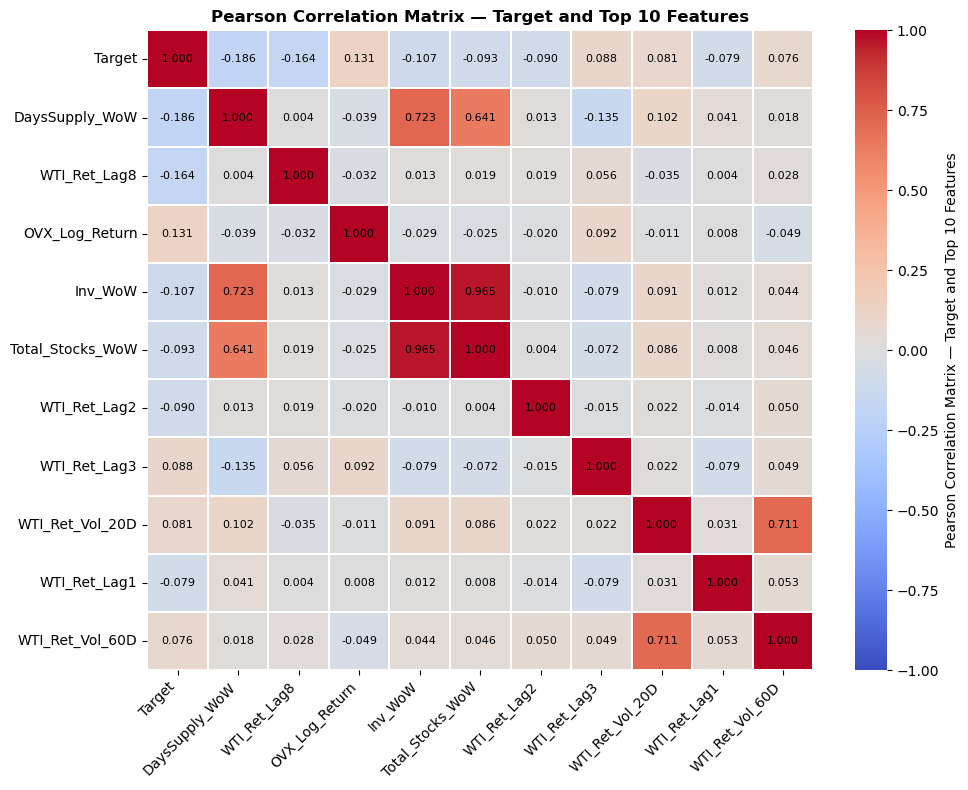

In [15]:
plot_matrix(pearson_comp, 'Pearson Correlation Matrix — Target and Top 10 Features', 
            vmin=-1, figname='PearsonCorr')

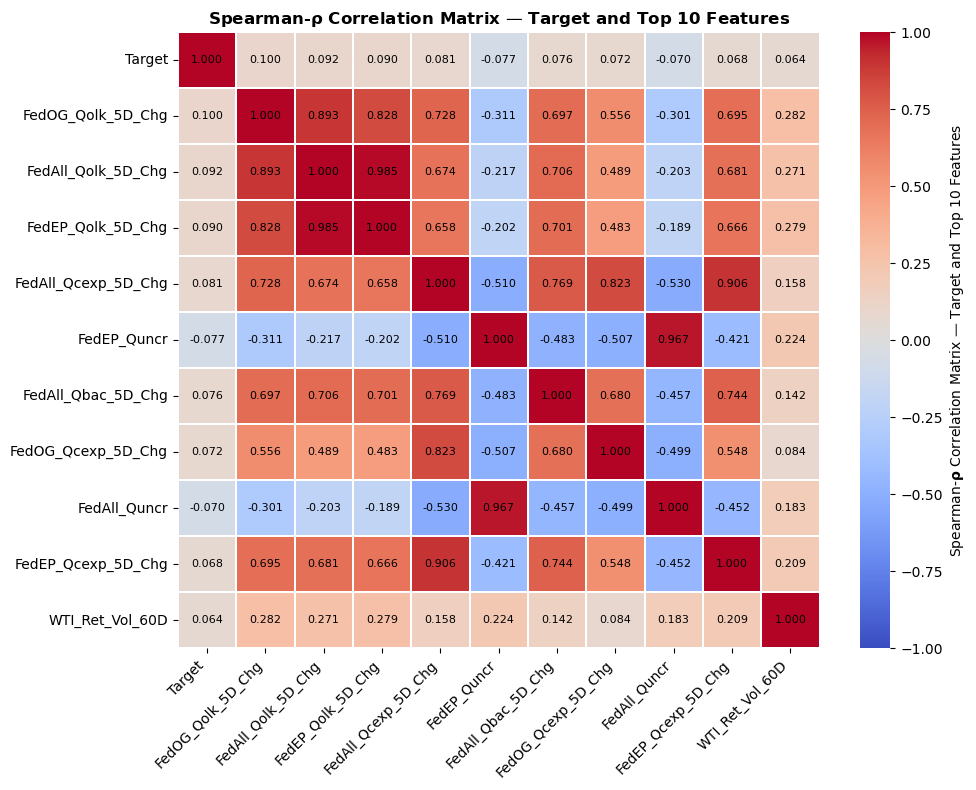

In [16]:
plot_matrix(spearman_comp, r'Spearman-$\mathbf{\rho}$ Correlation Matrix — Target and Top 10 Features', 
            vmin=-1, figname='SpearmanCorr')

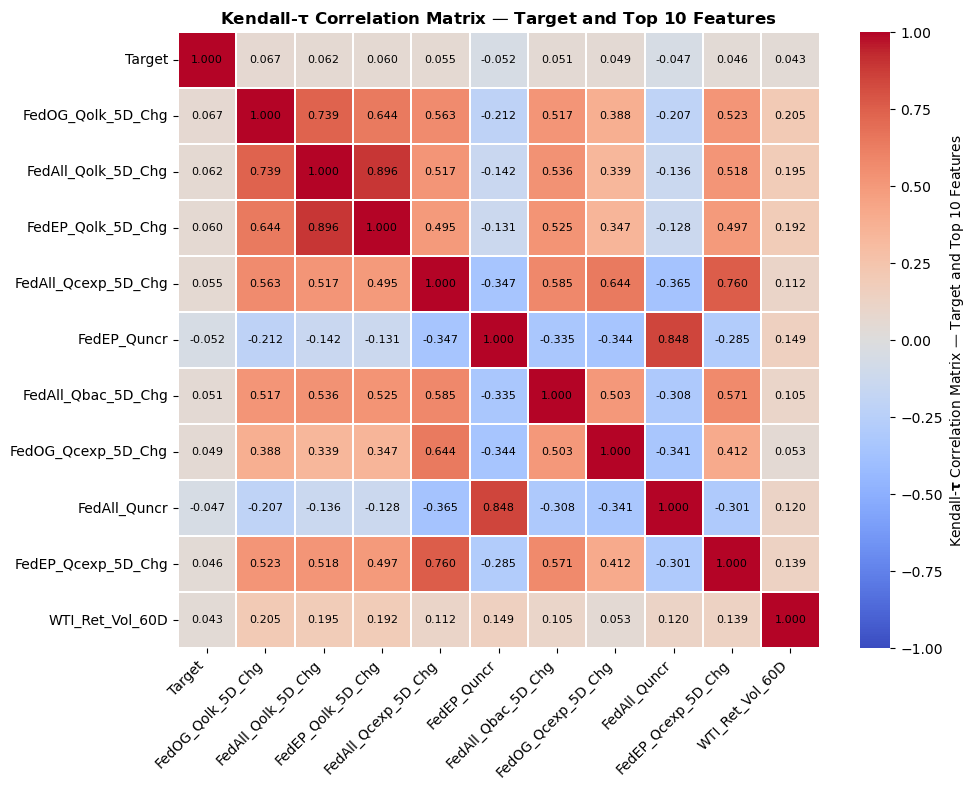

In [17]:
plot_matrix(kendall_comp, r'Kendall-$\mathbf{\tau}$ Correlation Matrix — Target and Top 10 Features', 
            vmin=-1, figname='KendallCorr')

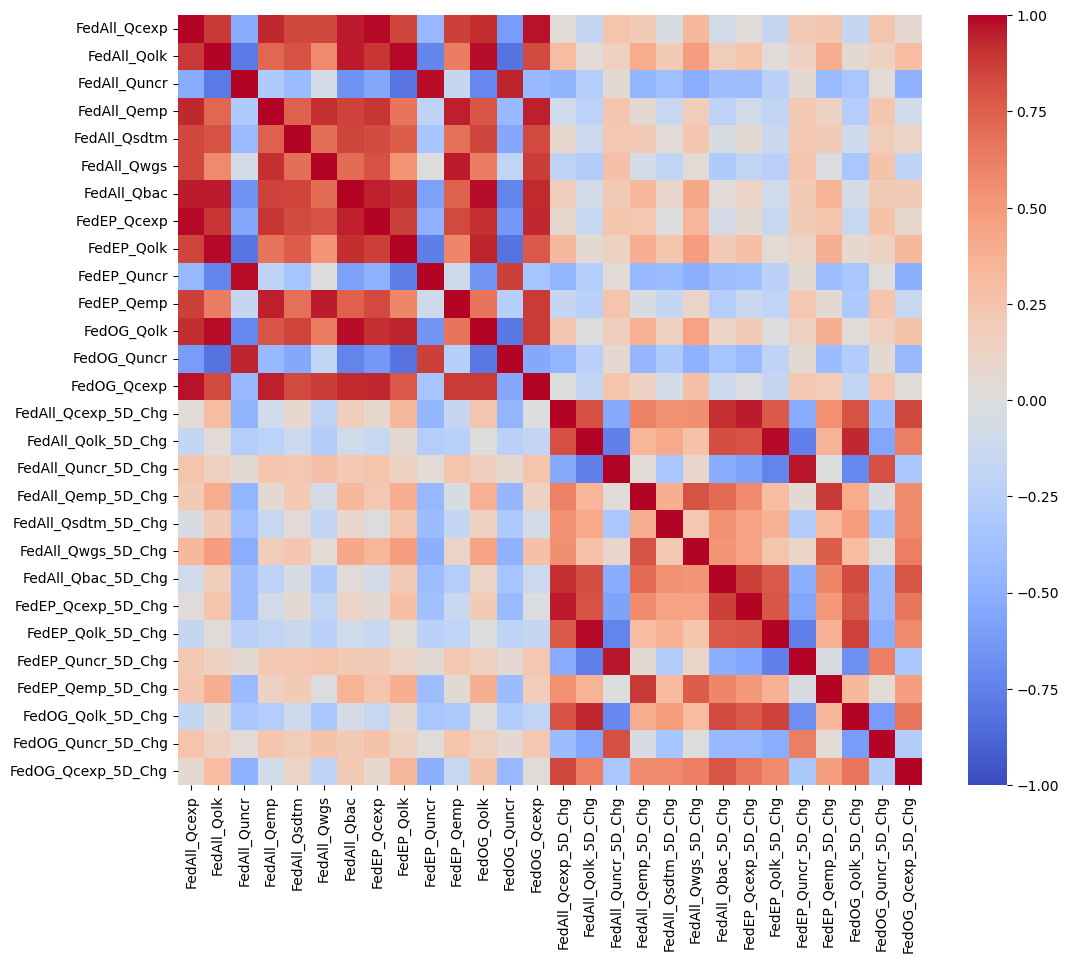

In [18]:
## Examine just the Fed features to check multicollinearity
fed_cols = [c for c in feature_cols if 'Fed' in c]
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(df[fed_cols].corr(method='pearson'), cmap='coolwarm', 
            vmin=-1, vmax=1, annot=False, fmt='.2f', ax=ax)
plt.show()

In [19]:
## Check relative linearity/nonlinearity of Fed features
pearson_fed = df[fed_cols].corr(method='pearson')
spearman_fed = df[fed_cols].corr(method='spearman')
signed_diff = spearman_fed.abs() - pearson_fed.abs()
signed_diff_stack = (signed_diff.where(np.triu(np.ones(signed_diff.shape), k=1).astype(bool)).stack().reset_index()
                    .rename(columns={'level_0': 'Feature A', 'level_1': 'Feature B', 0: 'Spearman|r| - Pearson|r|'})
                    .sort_values('Spearman|r| - Pearson|r|', ascending=False))

print('Most nonlinear pairs (Spearman >> Pearson):')
print(signed_diff_stack.head(10).to_string(index=False))
print('\nMost linear pairs (Pearson >> Spearman):')
print(signed_diff_stack.tail(10).to_string(index=False))

Most nonlinear pairs (Spearman >> Pearson):
         Feature A          Feature B  Spearman|r| - Pearson|r|
        FedOG_Qolk  FedEP_Qolk_5D_Chg                  0.106953
      FedAll_Quncr        FedAll_Qwgs                  0.106794
        FedOG_Qolk FedAll_Qolk_5D_Chg                  0.102351
      FedAll_Quncr       FedAll_Qsdtm                  0.099238
      FedAll_Qsdtm  FedEP_Qolk_5D_Chg                  0.098261
      FedAll_Qsdtm        FedEP_Quncr                  0.095807
      FedAll_Qsdtm FedAll_Qolk_5D_Chg                  0.089652
      FedAll_Qsdtm FedEP_Quncr_5D_Chg                  0.088942
FedAll_Qolk_5D_Chg FedOG_Quncr_5D_Chg                  0.086252
       FedAll_Qwgs        FedOG_Quncr                  0.084751

Most linear pairs (Pearson >> Spearman):
          Feature A          Feature B  Spearman|r| - Pearson|r|
 FedAll_Qemp_5D_Chg  FedOG_Qolk_5D_Chg                 -0.164327
 FedAll_Qemp_5D_Chg FedAll_Qbac_5D_Chg                 -0.168719
 FedEP_Qcexp_5D

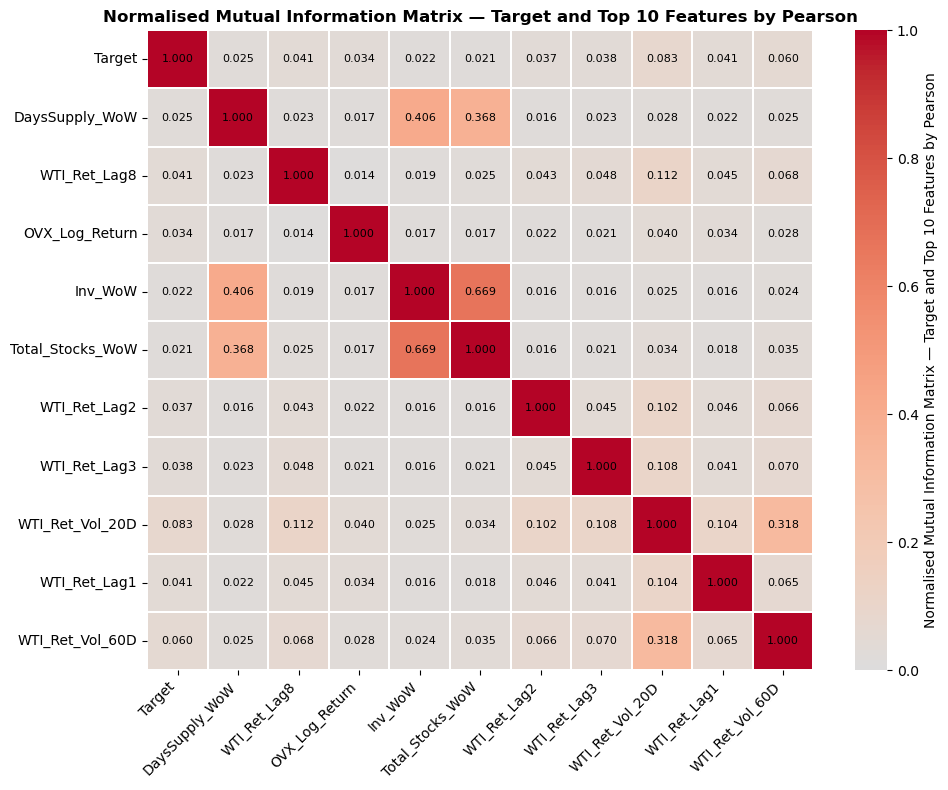

In [20]:
## NMI for top 10 features with highest Pearson with target
plot_matrix(nmi_comp, 'Normalised Mutual Information Matrix — Target and Top 10 Features by Pearson', 
            vmin=0, figname='TopPearson_NMI')

In [21]:
## Find the features with highest NMI with target
n_obs_full = df[feature_cols + [TARGET]].dropna().shape[0]
n_bins_full = int(np.ceil(np.log2(n_obs_full) + 1))
print(f"Sturges' formula: n={n_obs_full}, bins={n_bins_full}")

nmi_target = {}
for col in feature_cols:
    sub = df[[col, TARGET]].dropna()
    nmi_target[col] = normalised_mutual_information(sub[col].values, sub[TARGET].values, bins=n_bins_full)

nmi_target_series = pd.Series(nmi_target).sort_values(ascending=False)
top_nmi_cols = [TARGET] + nmi_target_series.head(10).index.tolist()
nmi_top = mi_matrix(df, top_nmi_cols, bins=n_bins_full)

Sturges' formula: n=1895, bins=12


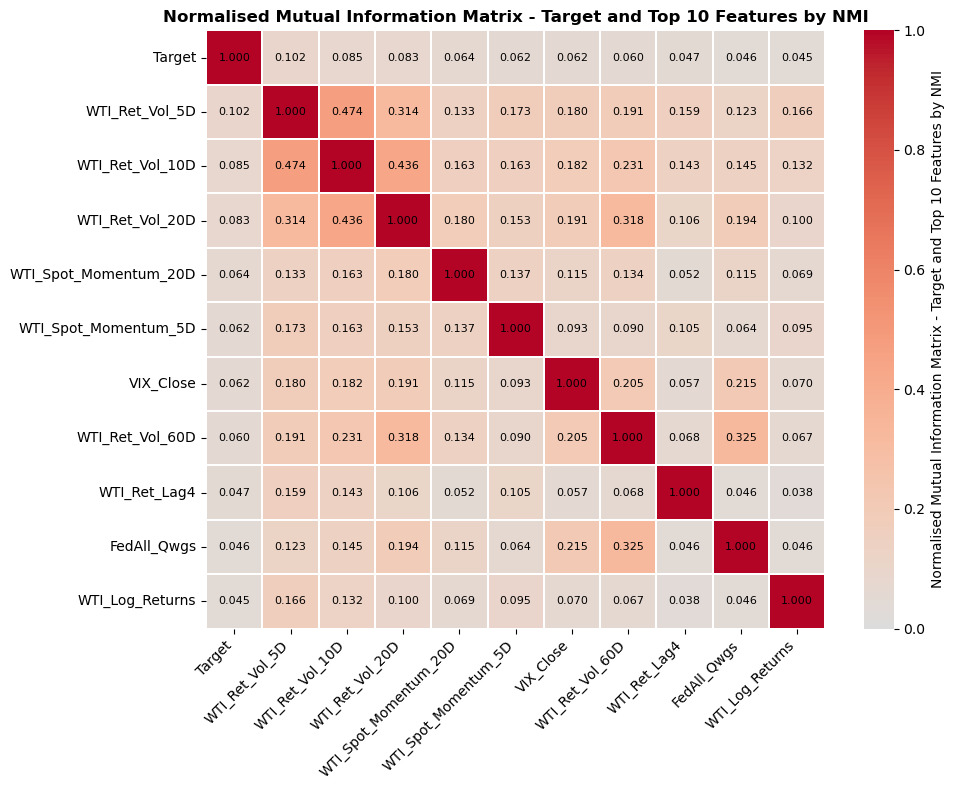

In [22]:
plot_matrix(nmi_top, 'Normalised Mutual Information Matrix - Target and Top 10 Features by NMI', 
            vmin=0, figname='TopNMI_NMI')

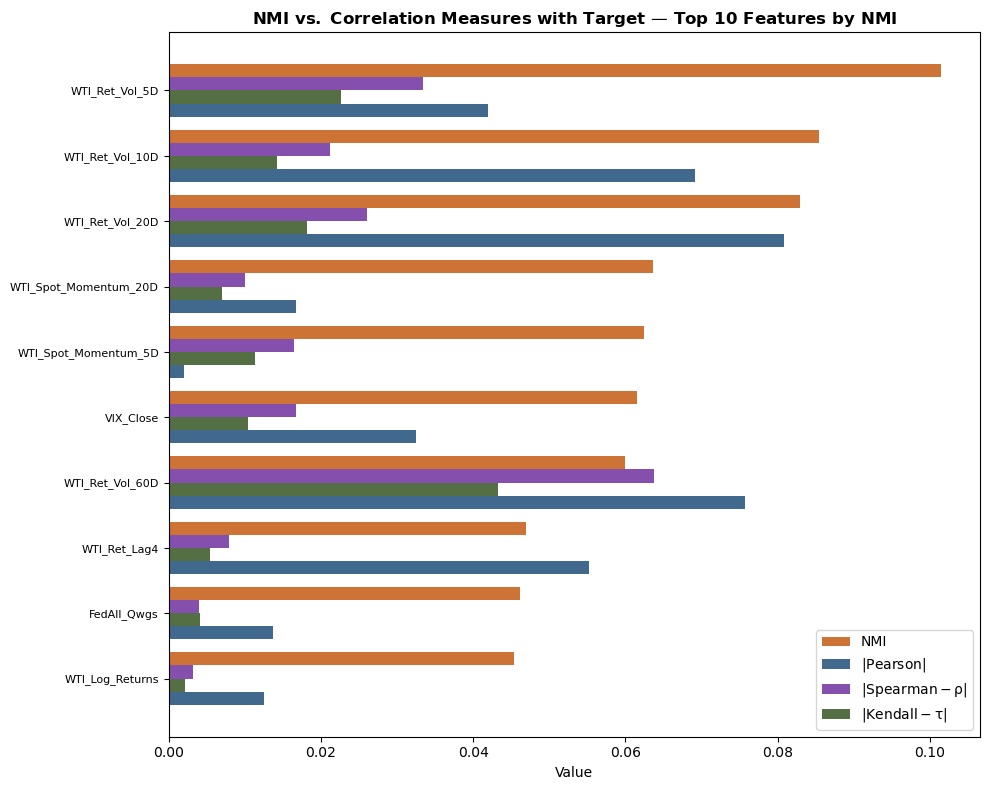


Features ranked notably higher by NMI than Pearson:
                       pearson_rank  spearman_rank  nmi_rank  rank_jump_pearson  rank_jump_spearman
WTI_Spot_Momentum_5D           74.0           48.0       5.0               69.0                43.0
FedAll_Qemp                    65.0           66.0      11.0               54.0                55.0
FedEP_Qemp                     66.0           63.0      12.0               54.0                51.0
WTI_Ret_Lag6                   68.0           74.0      14.0               54.0                60.0
WTI_Spot_Momentum_20D          54.0           56.0       4.0               50.0                52.0
FedAll_Qwgs                    57.0           68.0       9.0               48.0                59.0
WTI_Log_Returns                58.0           71.0      10.0               48.0                61.0
FedOG_Qcexp                    60.0           42.0      16.0               44.0                26.0
FedAll_Qcexp                   56.0           3

In [23]:
pearson_target = df[feature_cols + [TARGET]].corr(numeric_only=True)[TARGET].drop(TARGET).abs().sort_values(ascending=False)
spearman_target = df[feature_cols + [TARGET]].corr(method='spearman', numeric_only=True)[TARGET].drop(TARGET).abs().sort_values(ascending=False)
kendall_target = df[feature_cols + [TARGET]].corr(method='kendall', numeric_only=True)[TARGET].drop(TARGET).abs().sort_values(ascending=False)

comparison = pd.DataFrame({
    'pearson_abs':  pearson_target,
    'spearman_abs': spearman_target,
    'kendall_abs':  kendall_target,
    'nmi':          nmi_target_series,
}).dropna()

comparison['pearson_rank'] = comparison['pearson_abs'].rank(ascending=False)
comparison['spearman_rank'] = comparison['spearman_abs'].rank(ascending=False)
comparison['kendall_rank'] = comparison['kendall_abs'].rank(ascending=False)
comparison['nmi_rank'] = comparison['nmi'].rank(ascending=False)

## Rank jumps vs. each benchmark
comparison['rank_jump_pearson'] = comparison['pearson_rank'] - comparison['nmi_rank']
comparison['rank_jump_spearman'] = comparison['spearman_rank'] - comparison['nmi_rank']

top_n_bar = 10
plot_data = comparison.nlargest(top_n_bar, 'nmi')[['pearson_abs', 'spearman_abs', 'kendall_abs', 'nmi']].sort_values('nmi', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
y = np.arange(len(plot_data))
bar_height = 0.2

ax.barh(y + bar_height*1.5, plot_data['nmi'], bar_height, label='NMI', color='#c55a11', alpha=0.85)
ax.barh(y - bar_height*1.5, plot_data['pearson_abs'], bar_height, label=r'$|\mathrm{Pearson}|$', color='#1f4e79', alpha=0.85)
ax.barh(y + bar_height*0.5, plot_data['spearman_abs'], bar_height, label=r'$|\mathrm{Spearman-\rho}|$', color='#7030a0', alpha=0.85)
ax.barh(y - bar_height*0.5, plot_data['kendall_abs'], bar_height, label=r'$|\mathrm{Kendall-\tau}|$', color='#375623', alpha=0.85)

ax.set_yticks(y)
ax.set_yticklabels(plot_data.index, fontsize=8)
ax.set_xlabel('Value')
# ax.set_title(r'$\mathbf{NMI\ vs\ Correlation\ Measures\ with\ Target\ -\ Top\ 10\ Features\ by\ NMI}$')
ax.set_title(r'$\mathbf{NMI\ vs.\ Correlation\ Measures\ with\ Target}$' + 
             f' — Top {top_n_bar} Features by NMI', fontweight='bold')
ax.legend()
ax.axvline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.savefig('../Figures/RankJumps.pdf', bbox_inches='tight')
plt.show()

print('\nFeatures ranked notably higher by NMI than Pearson:')
print(comparison.nlargest(10, 'rank_jump_pearson')[['pearson_rank', 'spearman_rank', 'nmi_rank', 'rank_jump_pearson', 'rank_jump_spearman']].to_string())

print('\nFeatures ranked notably higher by NMI than Spearman:')
print(comparison.nlargest(10, 'rank_jump_spearman')[['pearson_rank', 'spearman_rank', 'nmi_rank', 'rank_jump_pearson', 'rank_jump_spearman']].to_string())

### Filtered Correlation Networks

In [24]:
def create_graph(nodes, edges, graph_type='full'):
    
    G = nx.Graph()
    
    all_edges = [(node_i, node_j, edges.loc[node_i, node_j])
    for i, node_i in enumerate(nodes)
    for j, node_j in enumerate(nodes)
    if j > i]

    all_edges.sort(key=lambda x: x[2])
    # print(all_edges)

    for node_i, node_j, d in all_edges:
        G.add_edge(node_i, node_j, weight=d)

    if graph_type == 'full':
        return G

    if graph_type == 'mst':
        MST = nx.minimum_spanning_tree(G)
        return MST
    
    if graph_type == 'pmfg':
        
        max_edges = 3 * len(nodes) - 6
        PMFG = nx.minimum_spanning_tree(G) # Start with MST; guaranteed planar

        checked = 0
        for node_i, node_j, d in all_edges:
            if PMFG.number_of_edges() >= max_edges:
                break
            if PMFG.has_edge(node_i, node_j):
                continue # Already in graph from MST
            PMFG.add_edge(node_i, node_j, weight=d)
            if not nx.is_planar(PMFG):
                PMFG.remove_edge(node_i, node_j)
            checked += 1
        
        print(f'Total Edges Checked for PMFG: {checked}')
        return PMFG
    
    if graph_type == 'tmfg':
        
        p = len(nodes)
        W = edges.values
        
        best_weight = -np.inf
        best_triple = None
        
        for i, j, k in itertools.combinations(range(p), 3):
            w = W[i, j] + W[j, k] + W[i, k]
            if w > best_weight:
                best_weight = w
                best_triple = (i, j, k)        

        u1, u2, u3 = best_triple

        N = {u1, u2, u3}
        E = set()
        T = {frozenset([u1, u2, u3])}

        E.add(frozenset([u1, u2]))
        E.add(frozenset([u2, u3]))
        E.add(frozenset([u1, u3]))

        while len(N) < p:
            best_gain = -np.inf
            best_n = None
            best_t = None

            for t in T:
                j1, j2, j3 = list(t)
                for n in range(p):
                    if n in N:
                        continue
                    gain = W[n, j1] + W[n, j2] + W[n, j3]
                    if gain > best_gain:
                        best_gain = gain
                        best_n = n
                        best_t = (j1, j2, j3)

            j1, j2, j3 = best_t

            ## Remove old triangle, add three new ones containing v
            T.discard(frozenset([j1, j2, j3]))
            T.add(frozenset([best_n, j1, j2]))
            T.add(frozenset([best_n, j2, j3]))
            T.add(frozenset([best_n, j3, j1]))

            ## Add v to vertex set and its three new edges
            N.add(best_n)
            E.add(frozenset([best_n, j1]))
            E.add(frozenset([best_n, j2]))
            E.add(frozenset([best_n, j3]))

        TMFG = nx.Graph()
        TMFG.add_nodes_from(nodes)

        for edge in E:
            i, j = list(edge)
            TMFG.add_edge(nodes[i], nodes[j], weight=float(W[i, j]))

        return TMFG   

In [25]:
def plot_graph(G, name, figname, cent_df=None, weight_matrix=None):
    
    fig, ax = plt.subplots(figsize=(16, 12))
    pos = nx.spring_layout(G, seed=12, iterations=100)
    cmap = plt.cm.coolwarm

    if cent_df is not None:
        degrees = cent_df['Degree']
        node_sizes = [300 + 3000 * degrees.get(n, 0) for n in G.nodes()]
    else:
        node_sizes = 300    

    if cent_df is not None:
        between = cent_df['Betweenness']
        norm_b = plt.Normalize(vmin=min(between.values), vmax=max(between.values))
        node_colors = [cmap(norm_b(between.get(n, 0))) for n in G.nodes()]
    else:
        node_colors = '#c55a11'        
        
    if weight_matrix is not None:
        edge_weights = []
        for u, v in G.edges():
            nmi_val = weight_matrix.loc[u, v] if u in weight_matrix.index else 0
            # edge_weights.append(0.5 + 5 * nmi_val)
            edge_weights.append(nmi_val)

        edge_widths = [0.5 + 5 * w for w in edge_weights]
        norm_e = plt.Normalize(vmin=min(edge_weights), vmax=max(edge_weights))
        
        ## Choose whether or not to implement edge colors
        # edge_colors = [plt.cm.Blues(norm_e(w)) for w in edge_weights]
        edge_colors = 'black'
    else:
        edge_widths = [d.get('weight', 0.5) for _, _, d in G.edges(data=True)]
        edge_colors = 'black'
        
    nx.draw_networkx_edges(G, pos, ax=ax, width=edge_widths, edge_color=edge_colors, alpha=0.4)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_sizes, node_color=node_colors, alpha=0.85)
    nx.draw_networkx_labels(G, pos, ax=ax,font_size=6, font_color='black')
    
    if cent_df is not None:
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm_b)
        sm.set_array([])
        plt.colorbar(sm, ax=ax, label='Betweenness Centrality', shrink=0.5)    

    ax.axis('off')
    ax.set_title(f'{name} Graph Representation of NMI Distance Network', fontweight='bold')
    plt.savefig(f'../Figures/{figname}.pdf', bbox_inches='tight')
    plt.show()

In [26]:
def compute_centralities(G, weight_type='min'):
 
    '''
    weight_type='min' : edges store distances (PMFG/MST)
                        betweenness uses G directly (shorter = stronger path)
                        eigenvector uses inverted weights (higher = more influence)
    weight_type='max' : edges store similarities (TMFG)
                        betweenness uses inverted weights
                        eigenvector uses G directly
    '''

    degree = nx.degree_centrality(G)
    
    G_inv = G.copy()
    for _, _, d in G_inv.edges(data=True):
        d['weight'] = 1 / (d['weight'] + 1e-12) 
            
    if weight_type == 'min':        
        
        betweenness = nx.betweenness_centrality(G, weight='weight', normalized=True)
        eigenvector = nx.eigenvector_centrality(G_inv,weight='weight', max_iter=1000)
        
    if weight_type == 'max':     
        
        betweenness = nx.betweenness_centrality(G_inv, weight='weight', normalized=True)
        eigenvector = nx.eigenvector_centrality(G, weight='weight', max_iter=1000)
        
    return pd.DataFrame({
        'Degree': degree,
        'Betweenness': betweenness,
        'Eigenvector': eigenvector}).sort_values('Degree', ascending=False)        

In [27]:
def plot_centralities(df, name, figname, top_n=10):
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 6))
    measures = ['Degree', 'Betweenness', 'Eigenvector']
    cmap = plt.cm.coolwarm    

    for ax, measure in zip(axes, measures):
        
        data = df[measure].sort_values(ascending=False).head(top_n).sort_values(ascending=True)
        norm = plt.Normalize(vmin=data.min(), vmax=data.max())
        colors = cmap(norm(data.values))
        
        ax.barh(data.index, data.values, color=colors, alpha=0.85)
        ax.set_title(f'{measure} Centrality', fontweight='bold')
        ax.set_xlabel('Score')
        ax.set_ylabel('Features')
        ax.tick_params(axis='y', labelsize=8)

    plt.suptitle(f'{name} Top {top_n} Nodes by Centrality', fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(f'../Figures/{figname}.pdf', bbox_inches='tight')
    plt.show()    

In [28]:
def plot_centrality_comparison(df, name, figname, n_labels=10):
    
    pairs = [('Degree', 'Betweenness'), ('Degree', 'Eigenvector'), ('Betweenness', 'Eigenvector')]
    fig, axes = plt.subplots(1, 3, figsize=(16, 6))
    cmap = plt.cm.coolwarm
    
    for ax, (x_col, y_col) in zip(axes, pairs):
        
        df['avg_rank'] = (df[x_col].rank(ascending=False) +
                  df[y_col].rank(ascending=False)) / 2
        
        norm = plt.Normalize(vmin=df['avg_rank'].min(), vmax=df['avg_rank'].max())
        colors = cmap(1 - norm(df['avg_rank'].values))
                             
        ax.scatter(df[x_col], df[y_col], color=colors, alpha=0.7, s=40)
        ax.set_xlabel(x_col, fontsize=9)
        ax.set_ylabel(y_col, fontsize=9)
        ax.set_title(f'{x_col} vs {y_col}', fontweight='bold')                             
                             
        for node, row in df.nsmallest(n_labels, 'avg_rank').iterrows():
            ax.annotate(node, (row[x_col], row[y_col]), fontsize=8, xytext=(4, 4),textcoords='offset points')

    plt.suptitle(f'{name} Centrality Comparisons', fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(f'../Figures/{figname}.pdf', bbox_inches='tight')
    plt.show()

In [29]:
nx.is_planar = lambda G: nx.check_planarity(G)[0]
nmi = mi_matrix(df, feature_cols, bins=n_bins_full)
## Clip for numerical stability, but in practice should be necessary since NMI already lies in [0, 1]
dist = np.sqrt(1 - nmi.clip(0, 1)) 

#### Complete Network

Nodes: 76
Edges: 2850
Expected Edges for Complete Network with 76 Features: 2850


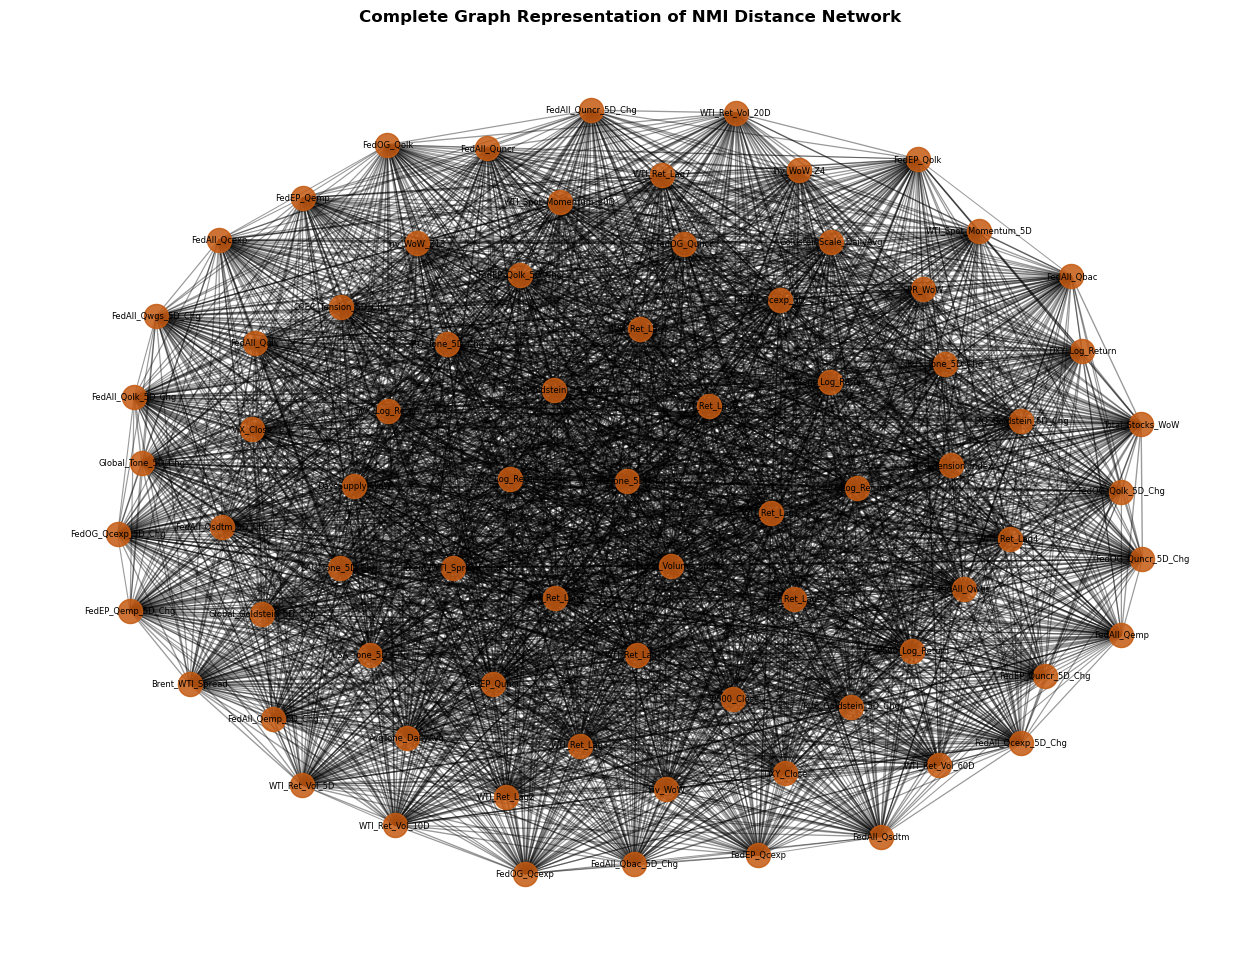

In [30]:
G_comp = create_graph(feature_cols, dist)                 

print(f'Nodes: {G_comp.number_of_nodes()}')
print(f'Edges: {G_comp.number_of_edges()}')
print(f'Expected Edges for Complete Network with {len(feature_cols)} Features: {len(feature_cols) * (len(feature_cols)-1) // 2}')

plot_graph(G_comp, 'Complete', figname='Complete_Graph')

#### Minimum Spanning Tree (MST)

Nodes: 76
Edges: 75
Expected Edges for MST Network with 76 Features: 75


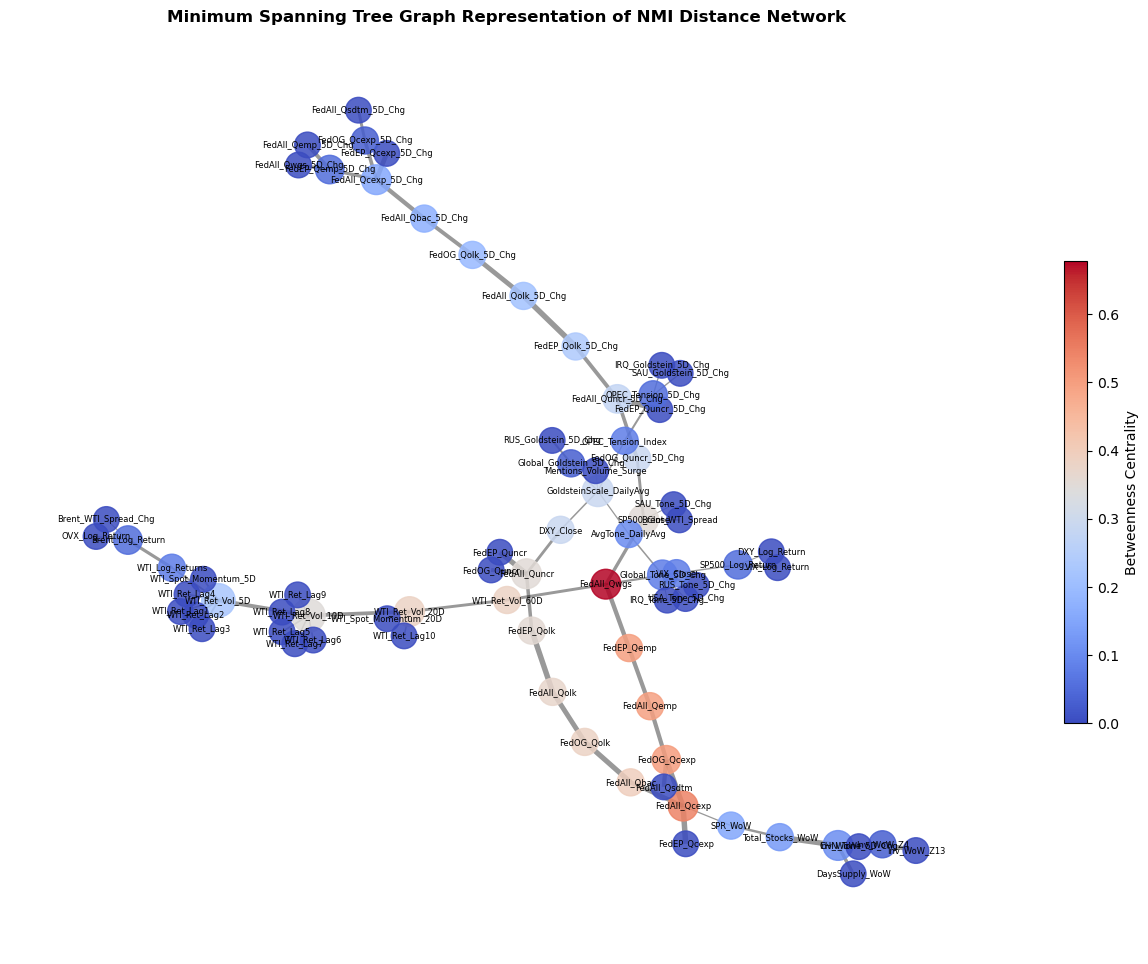

In [31]:
MST = create_graph(feature_cols, dist, 'mst')
cent_mst = compute_centralities(MST, weight_type='min') # MST uses distance weights, use weight_type='min'

print(f'Nodes: {MST.number_of_nodes()}')
print(f'Edges: {MST.number_of_edges()}')
print(f'Expected Edges for MST Network with {len(feature_cols)} Features: {len(feature_cols) - 1}')

plot_graph(MST, 'Minimum Spanning Tree', 'MST_Graph', cent_mst, nmi)

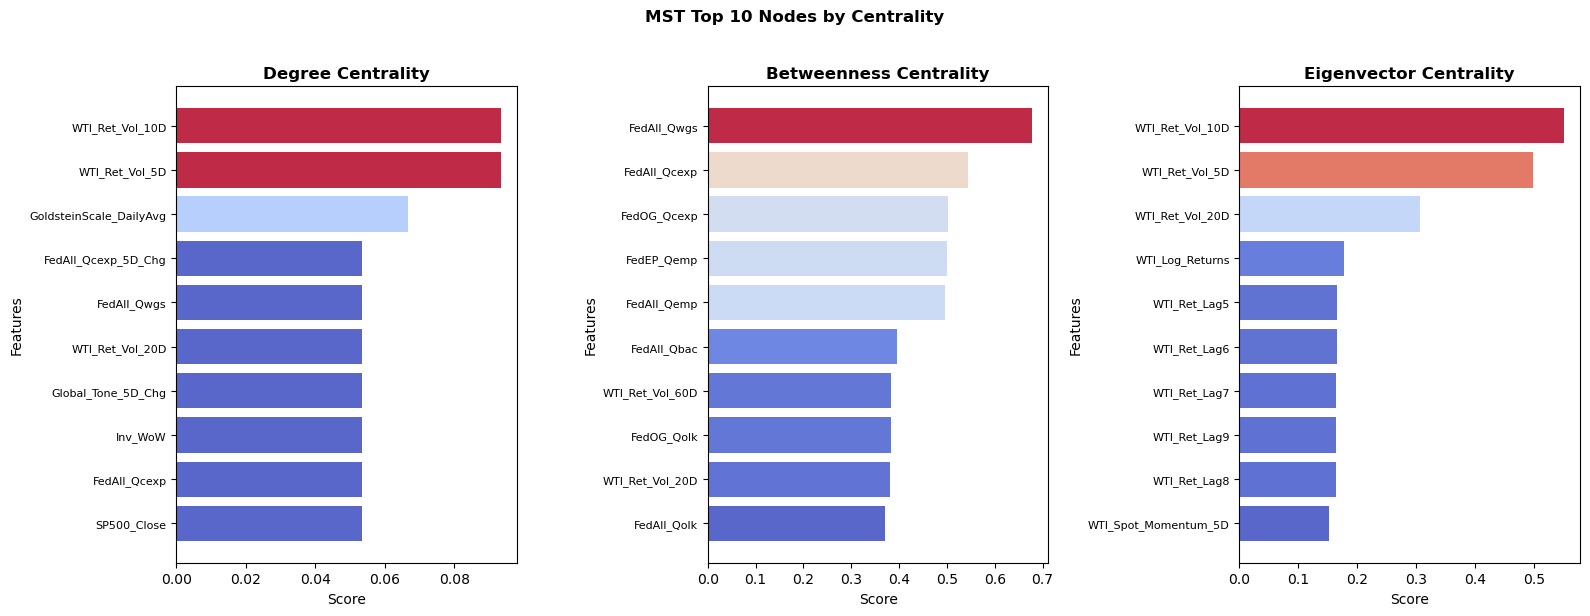

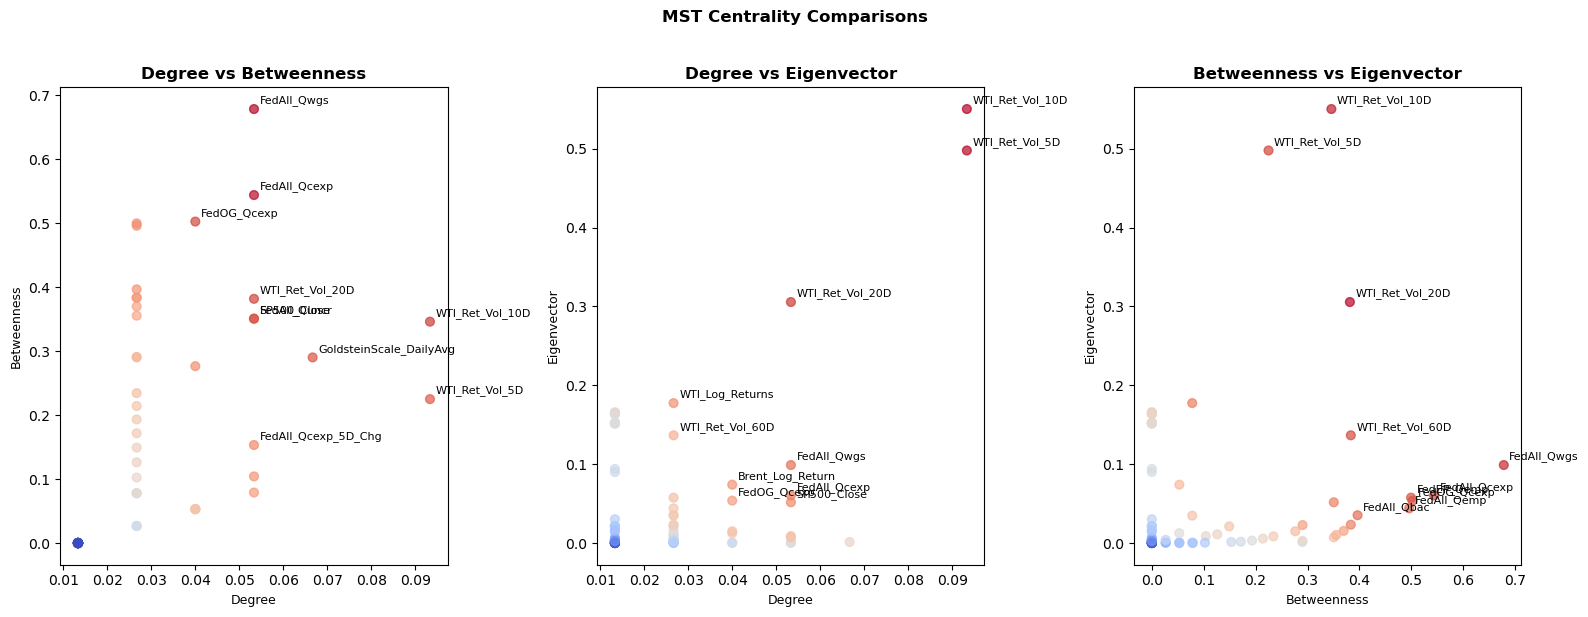

In [32]:
plot_centralities(cent_mst, 'MST', figname='MST_NodeCentrality')
plot_centrality_comparison(cent_mst, 'MST', figname='MST_CentralityComparison')

#### Planar Maximally Filtered Graph (PMFG)

Total Edges Checked for PMFG: 2224
Nodes: 76
Edges: 222
Expected Edges for PMFG Network with 76 Features: 222


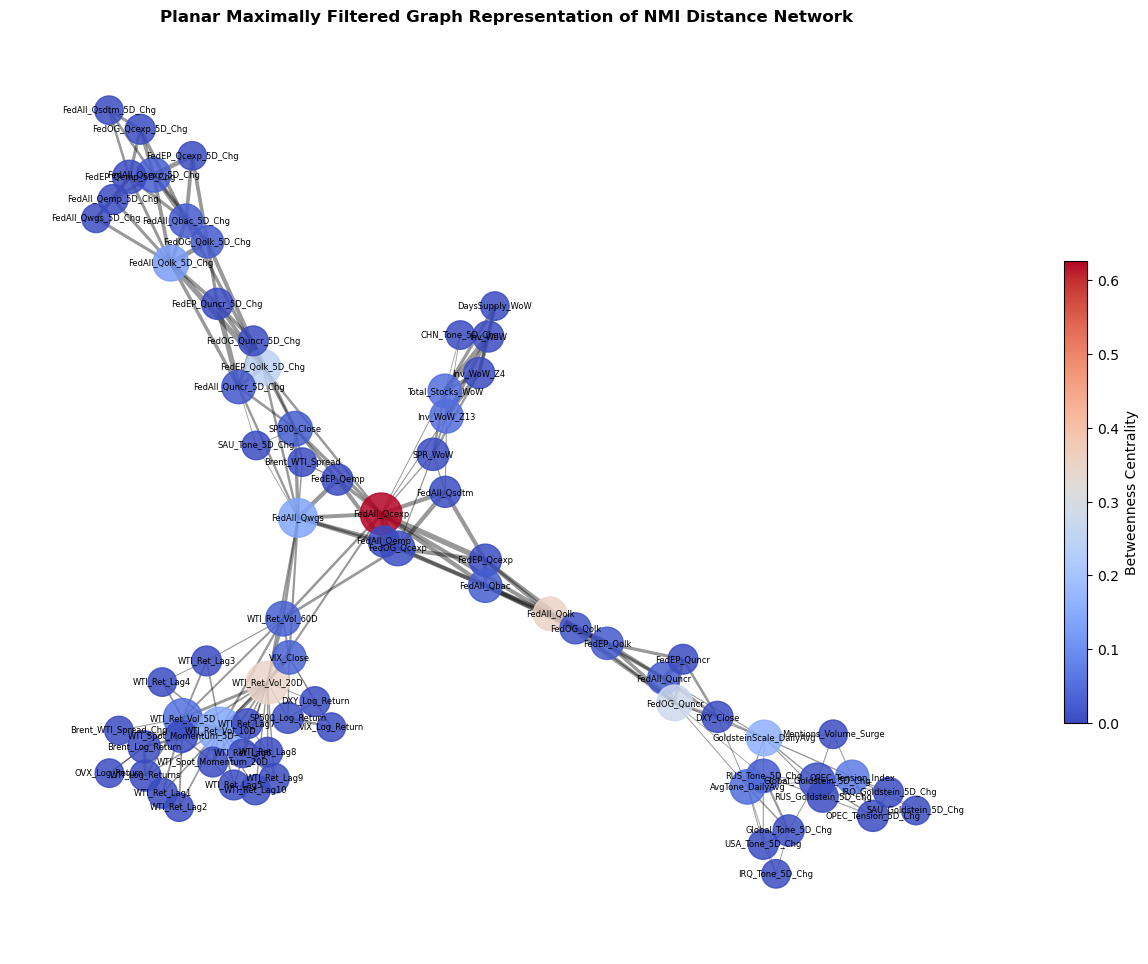

In [33]:
PMFG = create_graph(feature_cols, dist, 'pmfg')
cent_pmfg = compute_centralities(PMFG, weight_type='min') # PMFG uses distance weights, use weight_type='min'

print(f'Nodes: {PMFG.number_of_nodes()}')
print(f'Edges: {PMFG.number_of_edges()}')
print(f'Expected Edges for PMFG Network with {len(feature_cols)} Features: {3 * len(feature_cols) - 6}')

plot_graph(PMFG, 'Planar Maximally Filtered', 'PMFG_Graph', cent_pmfg, nmi)

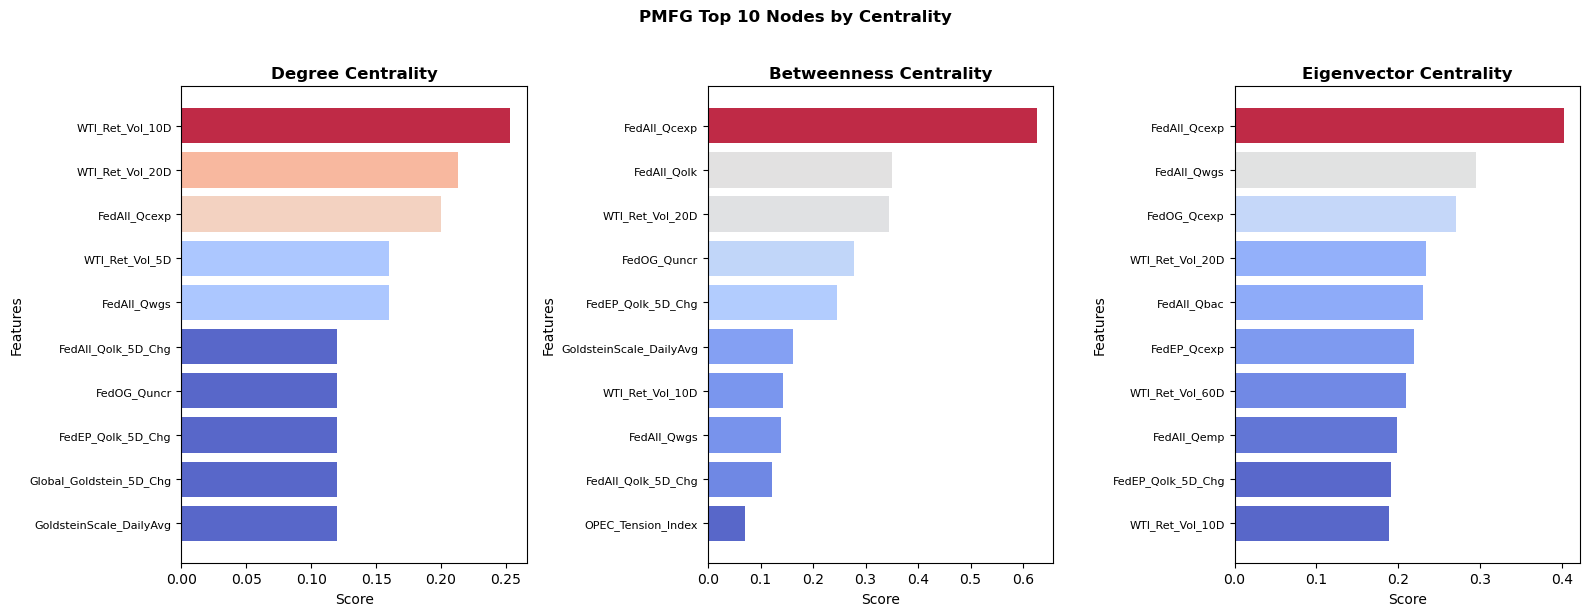

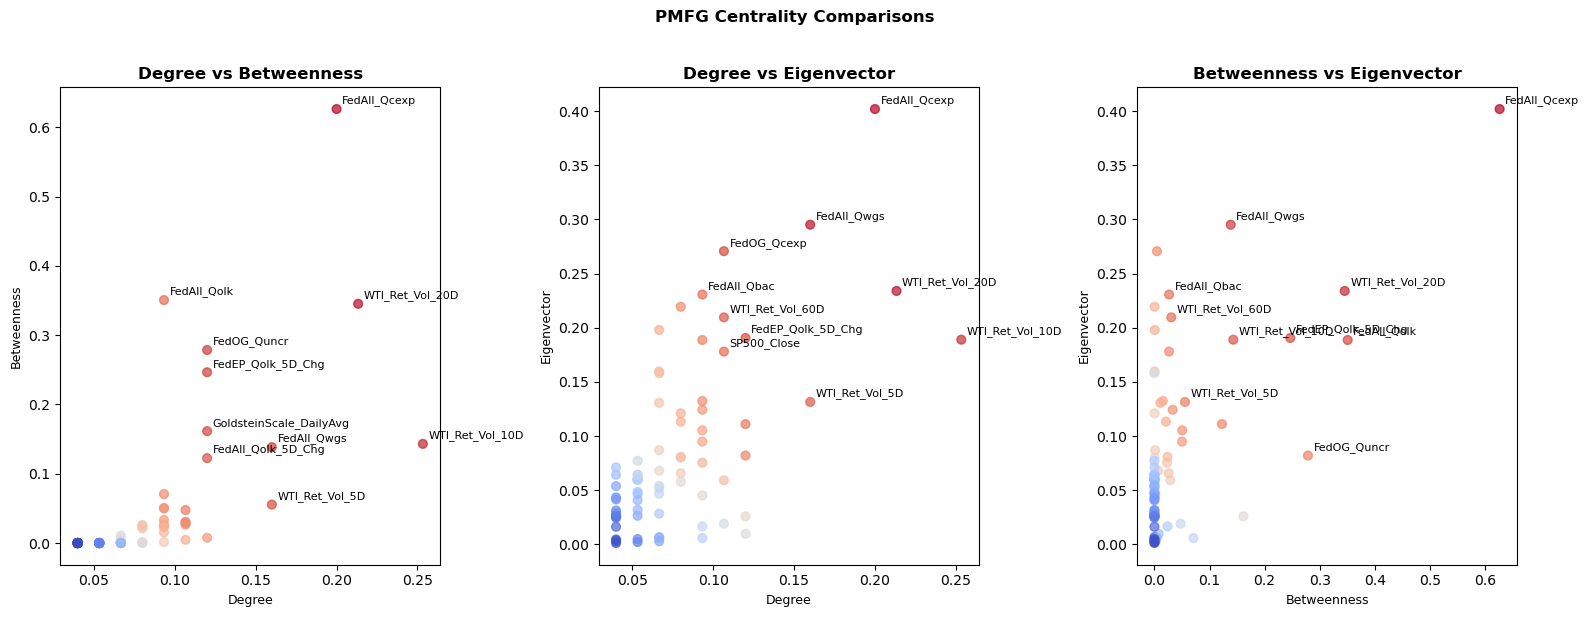

In [34]:
plot_centralities(cent_pmfg, 'PMFG', figname='PMFG_NodeCentrality')
plot_centrality_comparison(cent_pmfg, 'PMFG', figname='PMFG_CentralityComparison')

#### Triangulated Maximally Filtered Graph (TMFG)

Nodes: 76
Edges: 222
Expected Edges for TMFG Network with 76 Features: 222


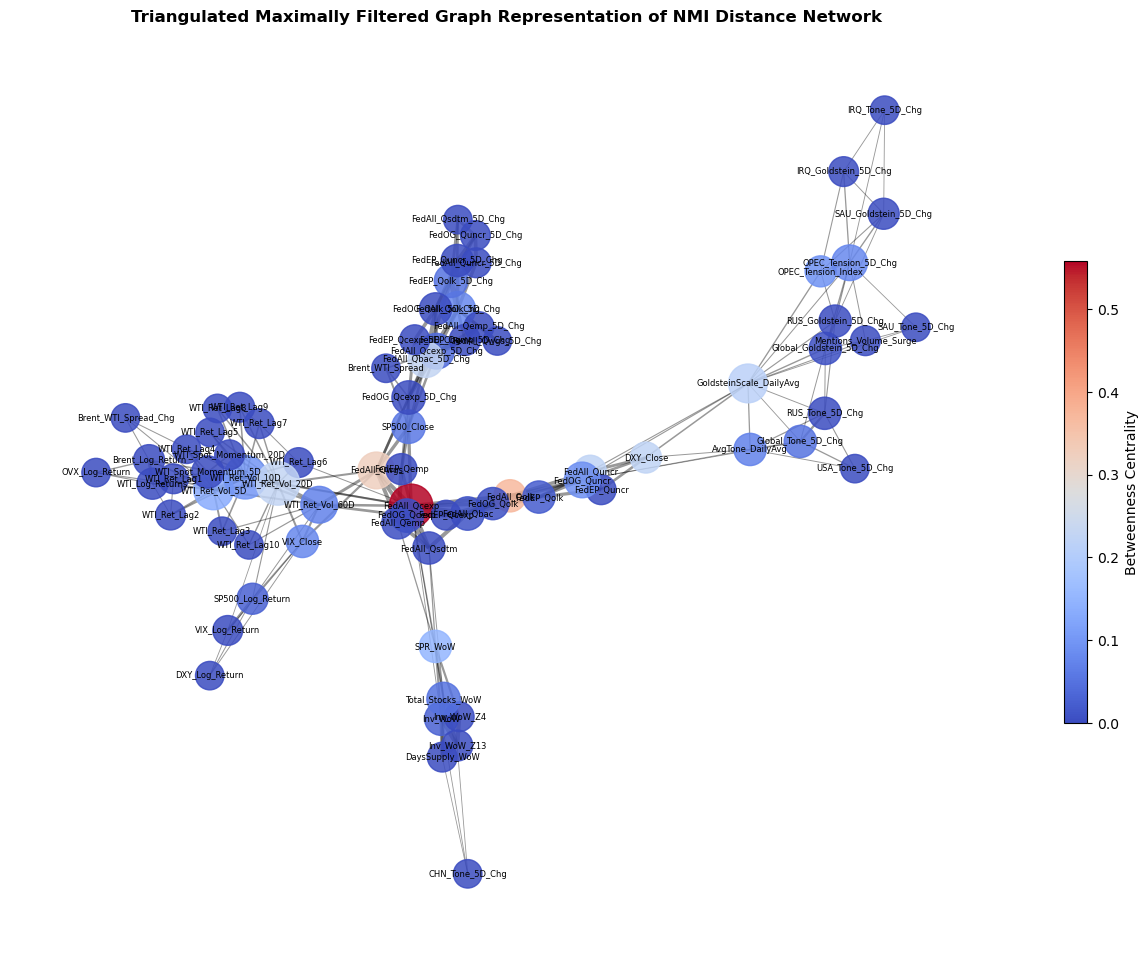

In [35]:
TMFG = create_graph(feature_cols, nmi, 'tmfg')
cent_tmfg = compute_centralities(TMFG, weight_type='max') # TMFG use raw NMI, use weight_type='max'

print(f'Nodes: {TMFG.number_of_nodes()}')
print(f'Edges: {TMFG.number_of_edges()}')
print(f'Expected Edges for TMFG Network with {len(feature_cols)} Features: {3 * len(feature_cols) - 6}')

plot_graph(TMFG, 'Triangulated Maximally Filtered', 'TMFG_Graph', cent_tmfg, nmi)

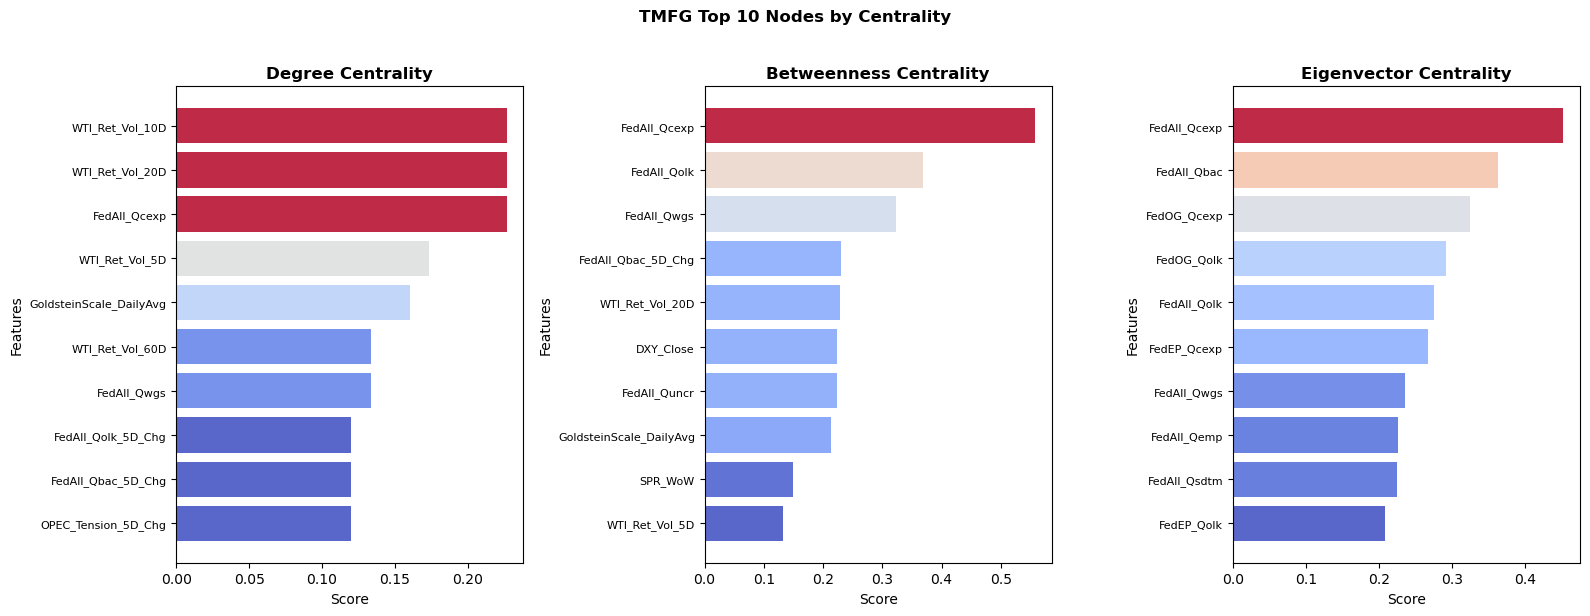

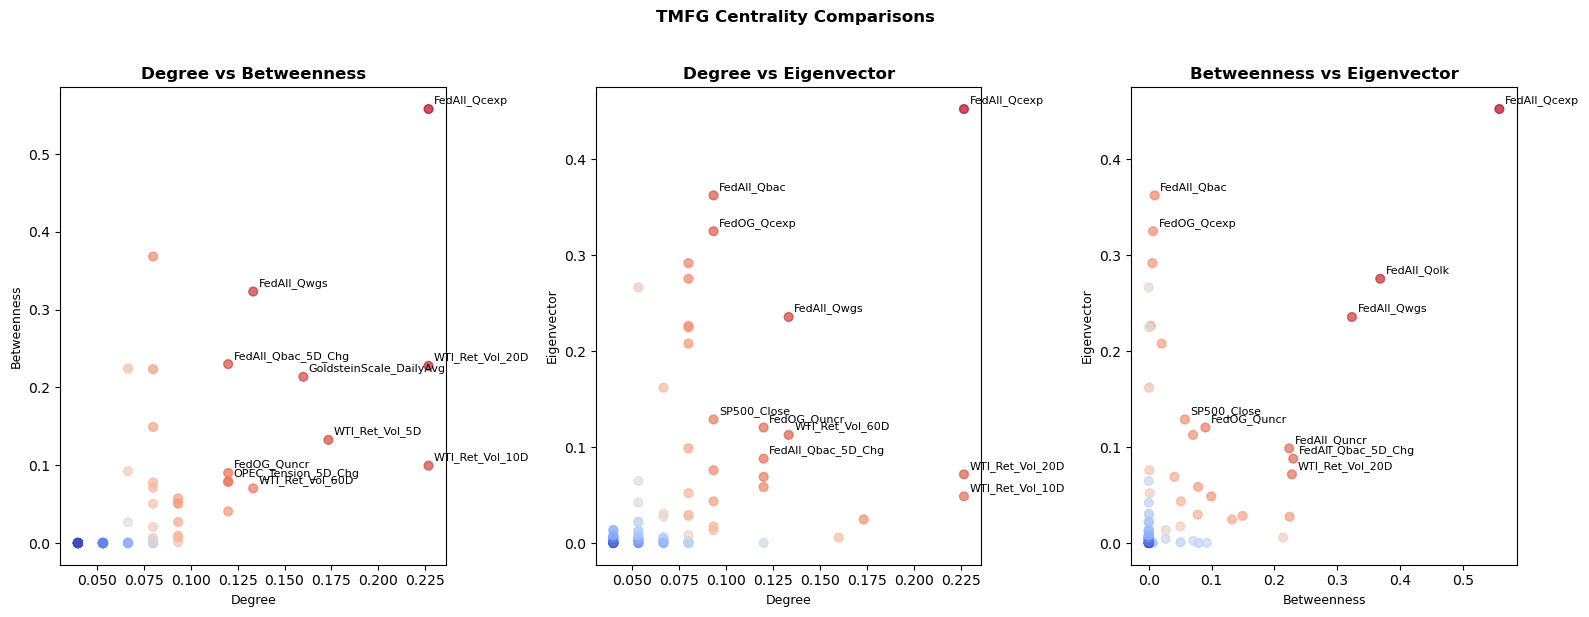

In [36]:
plot_centralities(cent_tmfg, 'TMFG', figname='TMFG_NodeCentrality')
plot_centrality_comparison(cent_tmfg, 'TMFG', figname='TMFG_CentralityComparison')

The MST, PMFG and TMFG are planar. The drawing layouts prioritise readability. The code checks planarity separately.

In [37]:
## Confirmation that all three network structures are indeed planar
print(f'MST planar?: {nx.check_planarity(MST)[0]}')
print(f'PMFG planar?: {nx.check_planarity(PMFG)[0]}')
print(f'TMFG planar?: {nx.check_planarity(TMFG)[0]}')

MST planar?: True
PMFG planar?: True
TMFG planar?: True


In [38]:
def compute_clustering_and_communities(G, graph_name):

    clustering = nx.clustering(G, weight='weight')
    clustering_series = pd.Series(clustering).sort_values(ascending=False)

    ## Use greedy modularity maximisation for community detection
    communities = nx_comm.greedy_modularity_communities(G, weight='weight')
    community_map = {}
    for i, community in enumerate(communities):
        for node in community:
            community_map[node] = i
    
    Q = nx_comm.modularity(G, communities, weight='weight')
    
    print(f'\n{graph_name} — {len(communities)} communities detected')
    print(f'Community sizes: {sorted([len(c) for c in communities], reverse=True)}')
    print(f'Modularity Q: {Q:.4f}')
    if graph_name != 'MST':
        print(f'\nTop 10 nodes by clustering coefficient:')
        print(clustering_series.head(10).round(4).to_string())

    return clustering_series, community_map, communities, Q

In [39]:
def plot_clustering(clustering_series, graph_name, figname, top_n=10):

    data = clustering_series.head(top_n).sort_values(ascending=True)
    cmap = plt.cm.coolwarm
    norm = plt.Normalize(vmin=data.min(), vmax=data.max())
    colors = cmap(norm(data.values))

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(data.index, data.values, color=colors, alpha=0.85)
    ax.set_title(f'Top {top_n} Nodes by Clustering Coefficient — {graph_name}', fontweight='bold')
    ax.set_xlabel('Clustering Coefficient')
    ax.tick_params(axis='y', labelsize=8)
    plt.tight_layout()
    plt.savefig(f'../Figures/{figname}.pdf', bbox_inches='tight')
    plt.show()

In [40]:
def plot_graph_communities(G, community_map, government_name, figname, 
                           cent_df=None, weight_matrix=None):

    fig, ax = plt.subplots(figsize=(12, 12))
    pos = nx.spring_layout(G, seed=12, iterations=100)
    
    n_communities = max(community_map.values()) + 1
    cmap = plt.cm.tab20c
    community_colors = [cmap(i / (n_communities - 1)) for i in range(n_communities)]
    node_colors = [community_colors[community_map.get(n, 0)] for n in G.nodes()]

    ## Node size determined by degree centrality
    if cent_df is not None:
        degrees = cent_df['Degree']
        node_sizes = [300 + 3000 * degrees.get(n, 0) for n in G.nodes()]
    else:
        node_sizes = 300

    ## Edge width determined by edge weights
    if weight_matrix is not None:
        edge_weights = []
        for u, v in G.edges():
            nmi_val = weight_matrix.loc[u, v] if u in weight_matrix.index else 0
            edge_weights.append(nmi_val)
        edge_widths = [0.3 + 2 * w for w in edge_weights]
    else:
        edge_widths = [d.get('weight', 0.5) for _, _, d in G.edges(data=True)]

    nx.draw_networkx_edges(G, pos, ax=ax, width=edge_widths,
                           edge_color='grey', alpha=0.4)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_sizes,
                           node_color=node_colors, alpha=0.85)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=6, font_color='black')

    ax.set_title(f'{government_name} — Node Colour: Community | Node Size: Degree',
                 fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    plt.savefig(f'../Figures/{figname}.pdf', bbox_inches='tight')
    plt.show()

In [41]:
def normalise_weights(G):

    G_norm = G.copy()
    weights = [d['weight'] for _, _, d in G_norm.edges(data=True)]
    max_weight = max(weights)
    for u, v, d in G_norm.edges(data=True):
        G_norm[u][v]['weight'] = d['weight'] / max_weight
    return G_norm

In [42]:
clust_mst, comm_map_mst, comms_mst, q_mst  = compute_clustering_and_communities(MST, 'MST')
clust_pmfg, comm_map_pmfg, comms_pmfg, q_pmfg = compute_clustering_and_communities(PMFG, 'PMFG')
clust_tmfg, comm_map_tmfg, comms_tmfg, q_tmfg = compute_clustering_and_communities(TMFG, 'TMFG')


MST — 10 communities detected
Community sizes: [10, 10, 10, 9, 9, 7, 6, 6, 5, 4]
Modularity Q: 0.7838

PMFG — 4 communities detected
Community sizes: [24, 19, 17, 16]
Modularity Q: 0.6596

Top 10 nodes by clustering coefficient:
IRQ_Tone_5D_Chg          0.9848
Mentions_Volume_Surge    0.9756
Brent_WTI_Spread_Chg     0.9686
SAU_Goldstein_5D_Chg     0.9669
VIX_Log_Return           0.9588
SAU_Tone_5D_Chg          0.9427
OVX_Log_Return           0.9405
WTI_Ret_Lag6             0.9311
WTI_Ret_Lag4             0.9166
WTI_Ret_Lag2             0.9161

TMFG — 5 communities detected
Community sizes: [24, 16, 15, 14, 7]
Modularity Q: 0.6403

Top 10 nodes by clustering coefficient:
FedEP_Qcexp            0.6549
FedAll_Quncr_5D_Chg    0.5704
FedEP_Qcexp_5D_Chg     0.5389
FedAll_Qwgs_5D_Chg     0.5223
Inv_WoW_Z4             0.5009
FedEP_Quncr            0.4801
FedAll_Qsdtm_5D_Chg    0.4641
FedOG_Quncr_5D_Chg     0.4603
FedAll_Qemp_5D_Chg     0.4531
FedOG_Qolk             0.4466


In [43]:
## Used to show that Q-scores do not change significantly with scaling
MST_norm = normalise_weights(MST)
PMFG_norm = normalise_weights(PMFG)
TMFG_norm = normalise_weights(TMFG)

q_mst = nx_comm.modularity(MST_norm, comms_mst,  weight='weight')
q_pmfg = nx_comm.modularity(PMFG_norm, comms_pmfg, weight='weight')
q_tmfg = nx_comm.modularity(TMFG_norm, comms_tmfg, weight='weight')

Q_scores = {'MST': q_mst, 'PMFG': q_pmfg, 'TMFG': q_tmfg}
print(Q_scores)

{'MST': 0.7837688910887303, 'PMFG': 0.6596453887114665, 'TMFG': 0.6402881238403684}


In [44]:
## Not used, because MST does not produce nonzero clustering coefficients
# plot_clustering(clust_mst, 'MST')

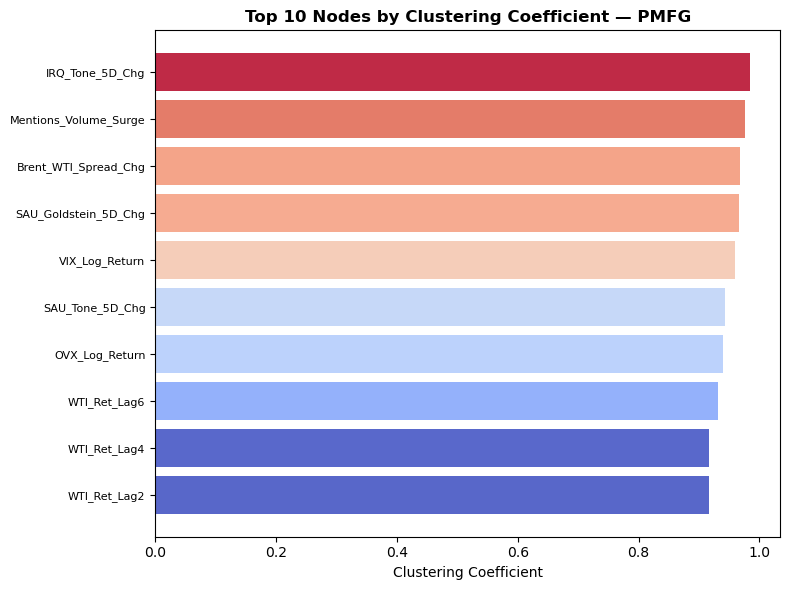

In [45]:
plot_clustering(clust_pmfg, 'PMFG', figname='PMFG_ClustCoeff')

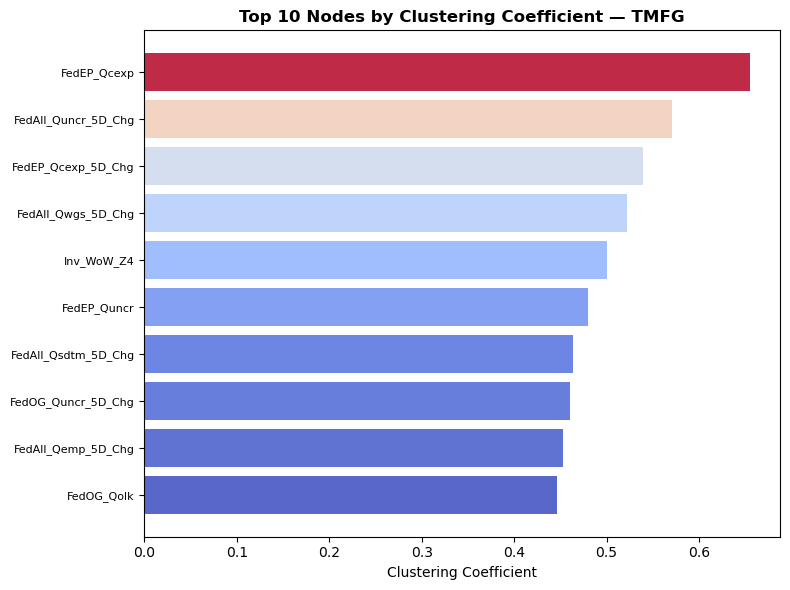

In [46]:
plot_clustering(clust_tmfg, 'TMFG', figname='TMFG_ClustCoeff')

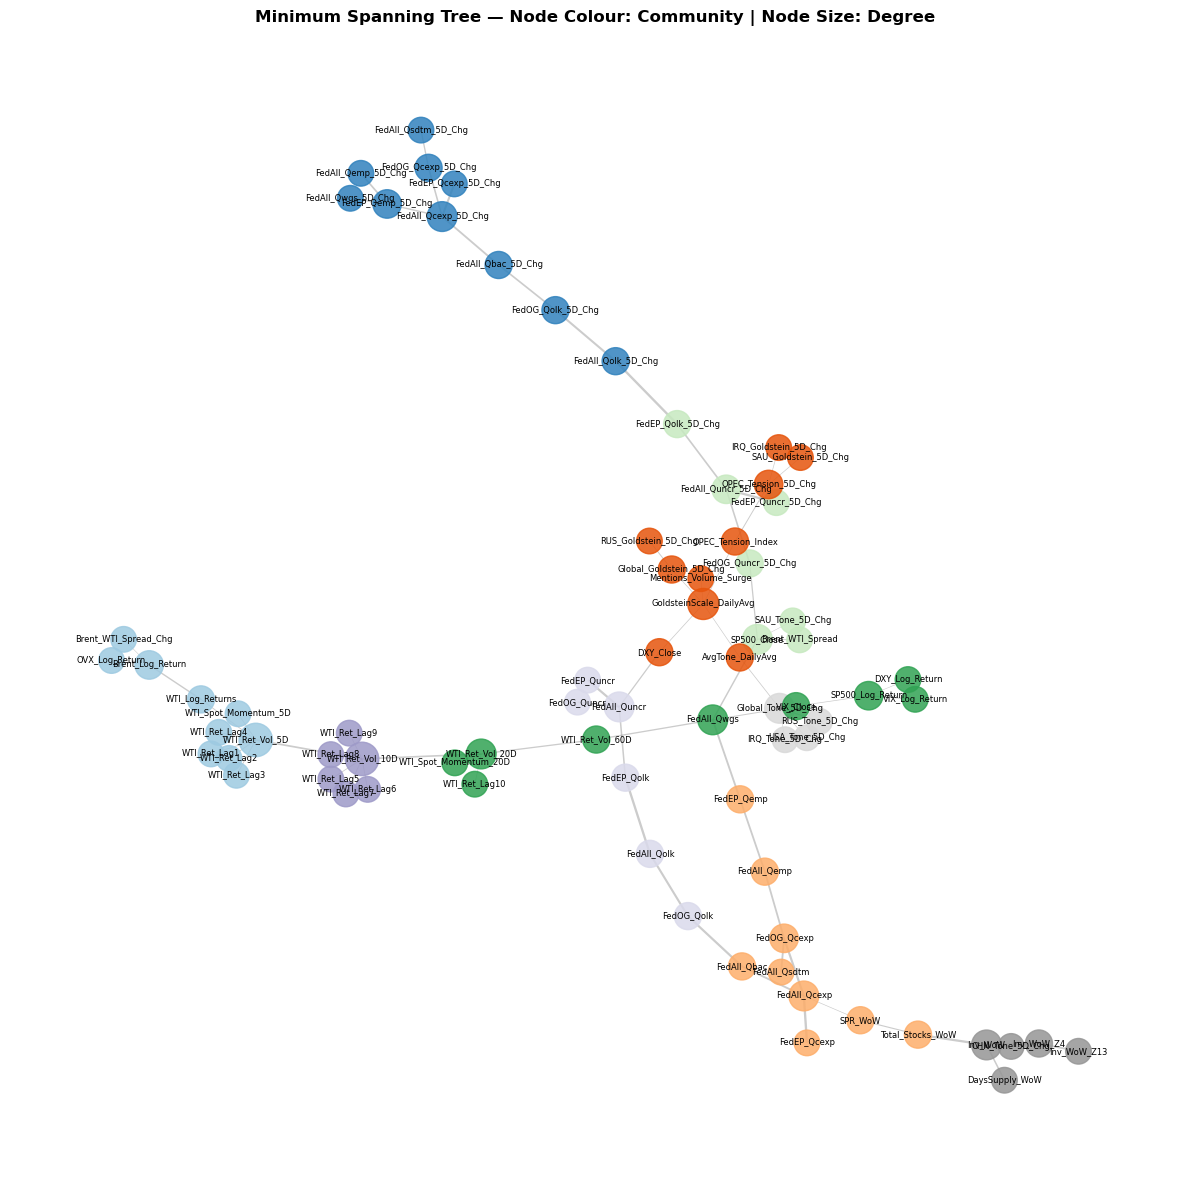

In [47]:
plot_graph_communities(MST, comm_map_mst, 'Minimum Spanning Tree', 
                       'MST_CommunityGraph', cent_mst, nmi)

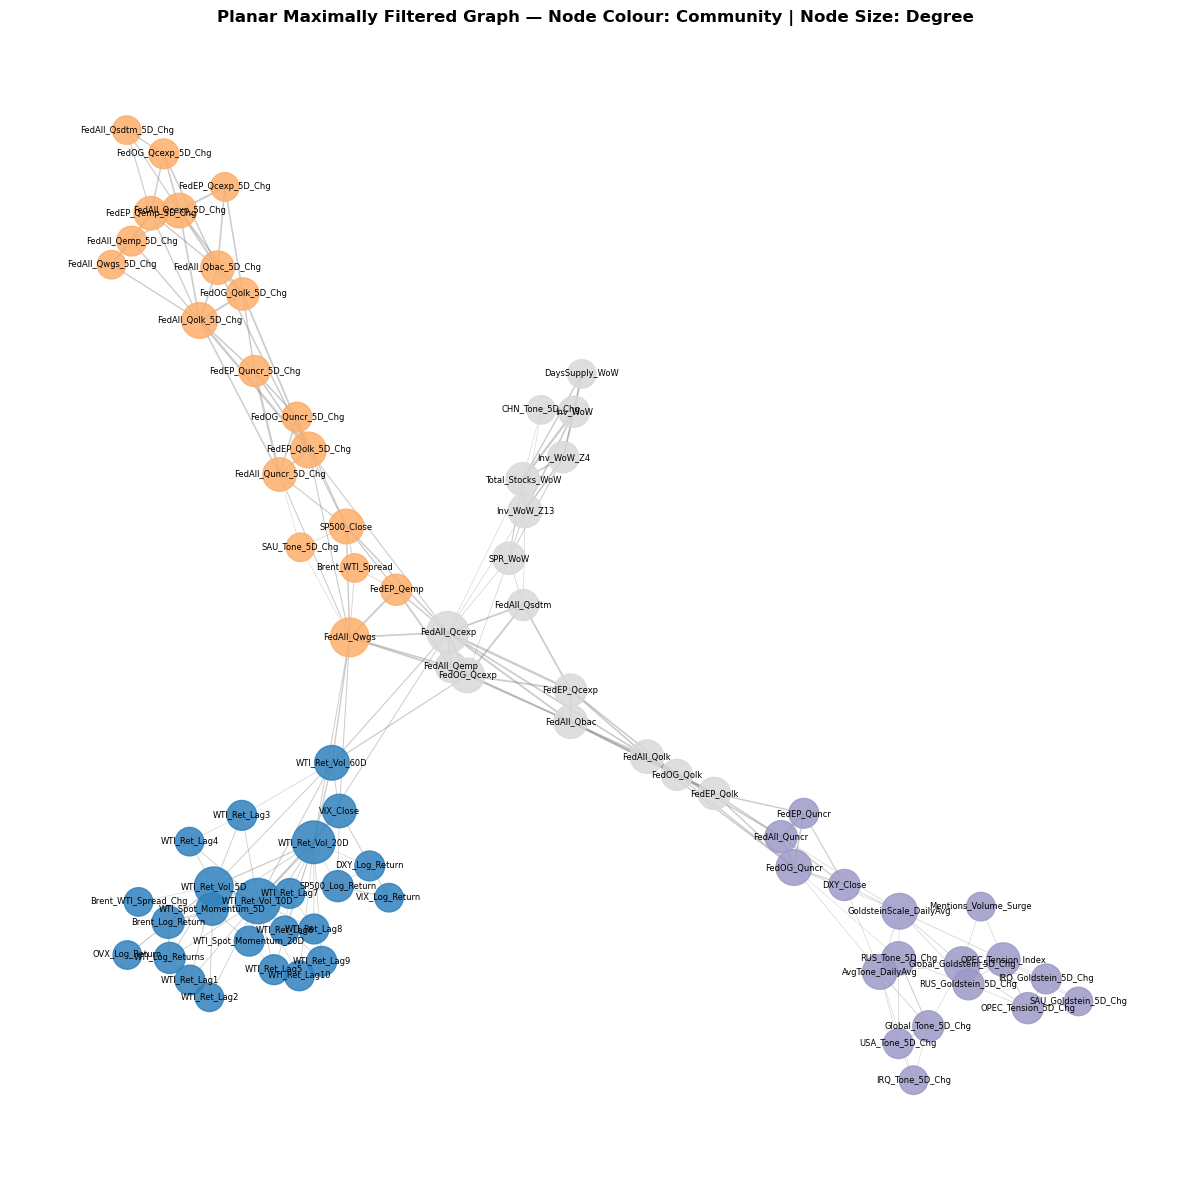

In [48]:
plot_graph_communities(PMFG, comm_map_pmfg, 'Planar Maximally Filtered Graph',
                       'PMFG_CommunityGraph', cent_pmfg, nmi)

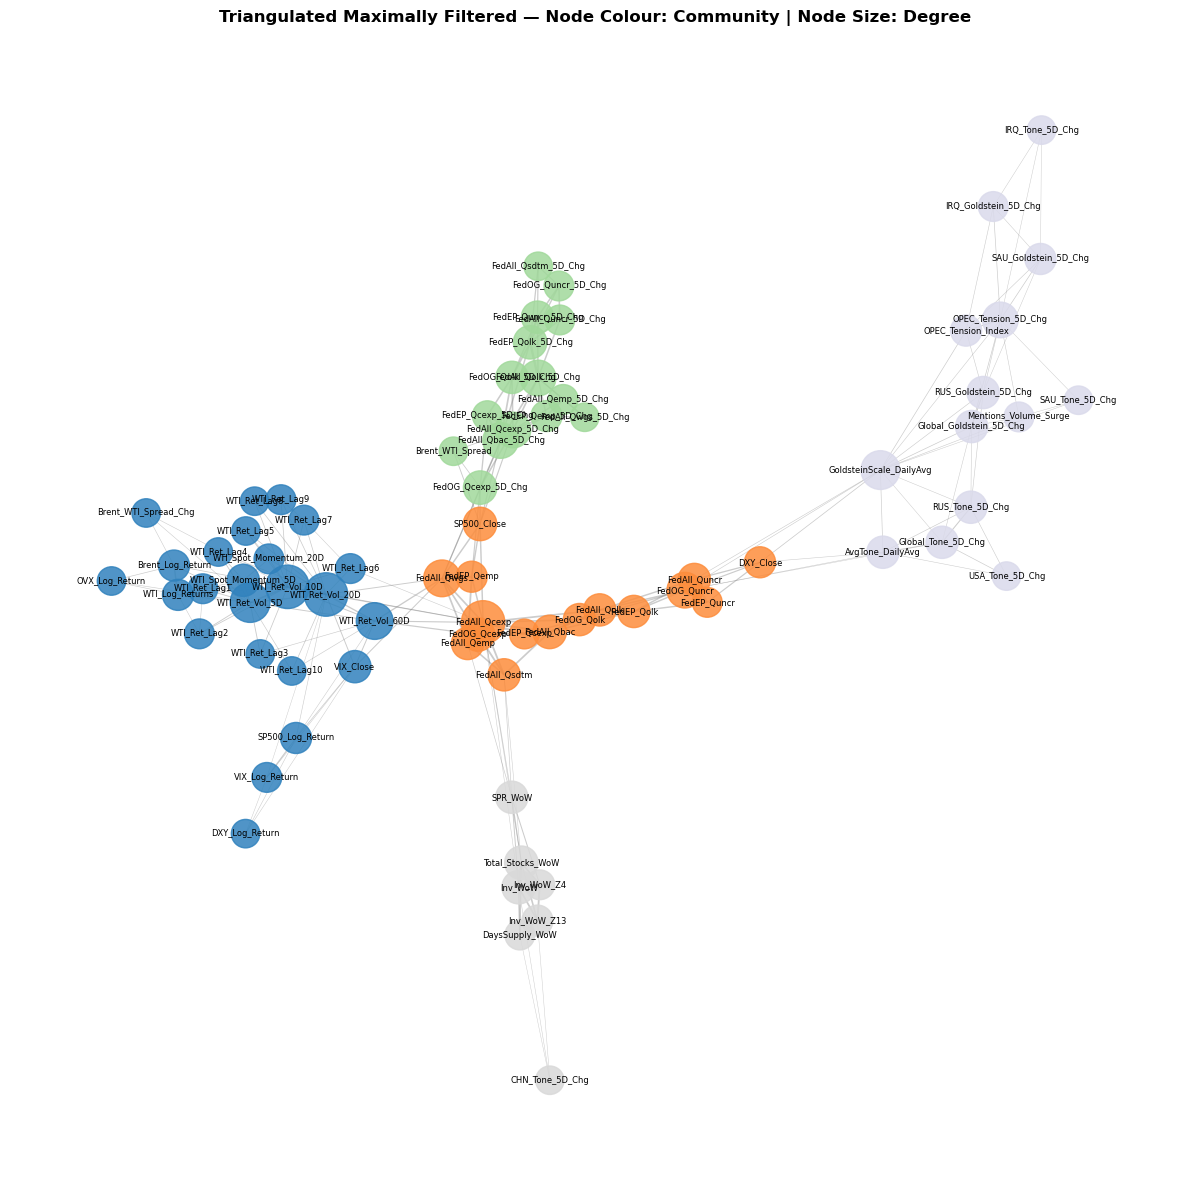

In [49]:
plot_graph_communities(TMFG, comm_map_tmfg, 'Triangulated Maximally Filtered', 
                       'TMFG_CommunityGraph', cent_tmfg, nmi)

### Directional Dependence

#### Granger Causality Tests

In [50]:
def check_stationarity(series, name, significance=0.05):
    
    ## ADF test for stationarity
    result = adfuller(series.dropna(), autolag='AIC')
    p_value = result[1]
    is_stationary = p_value < significance
    return is_stationary, p_value

In [51]:
def run_granger_causality(df, target_col, feature_cols, max_lag=5, significance=0.05):

    results = []

    target_stationary, target_p = check_stationarity(df[target_col], target_col)
    print(f'Target ({target_col}) stationary: {target_stationary} '
          f'(ADF p={target_p:.4f})')

    def _best_lag_result(gc_result, max_lag):
        
        ## Use AIC to select lag length
        best_lag, best_aic = None, np.inf
        for lag in range(1, max_lag + 1):
            unrestricted_aic = gc_result[lag][1][1].aic # OLS result for unrestricted model
            if unrestricted_aic < best_aic:
                best_aic = unrestricted_aic
                best_lag = lag
        best_f = gc_result[best_lag][0]['ssr_ftest'][0]
        best_p = gc_result[best_lag][0]['ssr_ftest'][1]
        return best_lag, best_f, best_p

    for feature in feature_cols:
        feat_stationary, feat_p = check_stationarity(df[feature], feature)
        sub = df[[target_col, feature]].dropna()

        ## Forward: feature -> target
        try:
            gc_fwd = grangercausalitytests(sub[[target_col, feature]].values, maxlag=max_lag, verbose=False)
            fwd_lag, fwd_f, fwd_p = _best_lag_result(gc_fwd, max_lag)
            fwd_sig = fwd_p < significance
        except Exception:
            fwd_lag = fwd_f_measure = fwd_f = fwd_p = None
            fwd_sig = False

        ## Reverse: target -> feature (for asymmetry)
        try:
            gc_rev = grangercausalitytests(sub[[feature, target_col]].values, maxlag=max_lag, verbose=False)
            rev_lag, rev_f, rev_p = _best_lag_result(gc_rev, max_lag)
            rev_sig = rev_p < significance
        except Exception:
            rev_lag = rev_f_measure = rev_f = rev_p = None
            rev_sig = False

        ## Asymmetry: positive = feature drives target more than reverse
        if fwd_f is not None and rev_f is not None:
            gc_asymmetry = fwd_f - rev_f
        else:
            gc_asymmetry = None

        results.append({
            'feature': feature,
            'best_lag': fwd_lag,
            'f_measure': fwd_f_measure,
            'f_statistic': fwd_f,
            'p_value': fwd_p,
            'significant': fwd_sig,
            'rev_lag': rev_lag,
            'rev_f_measure': rev_f_measure,
            'rev_f_statistic': rev_f,
            'rev_p_value': rev_p,
            'rev_significant': rev_sig,
            'gc_asymmetry': gc_asymmetry,
            'feat_stationary': feat_stationary,
            'feat_adf_p': feat_p,
        })

    gc_df = pd.DataFrame(results).sort_values('p_value')
    return gc_df

In [52]:
def plot_granger_results(gc_df, title='Granger Causality Results', figname=None, top_n=20):

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    cmap = plt.cm.coolwarm

    plot_fwd = (gc_df[gc_df['feat_stationary']].dropna(subset=['p_value'])
               .nsmallest(top_n, 'p_value').sort_values('p_value', ascending=False))
        
    neg_log_p = -np.log10(plot_fwd['p_value'].clip(1e-10))
    threshold = -np.log10(0.05)

    norm_fwd  = plt.Normalize(vmin=neg_log_p.min(), vmax=neg_log_p.max())
    colors_fwd = cmap(norm_fwd(neg_log_p.values))

    axes[0].barh(plot_fwd['feature'], neg_log_p, color=colors_fwd, alpha=0.85)
    axes[0].axvline(threshold, color='black', linewidth=1,
                    linestyle='--', label='p = 0.05')
    axes[0].set_xlabel(r'$-\log_{10}(p\mathrm{-value})$')
    axes[0].set_ylabel('Features')
    axes[0].set_title(r'Causal Influence of Features on Target Variable', fontweight='bold')
    axes[0].tick_params(axis='y', labelsize=8)
    axes[0].legend()

    sm0 = plt.cm.ScalarMappable(cmap=cmap, norm=norm_fwd)
    sm0.set_array([])
    plt.colorbar(sm0, ax=axes[0], label=r'$-\log_{10}(p\mathrm{-value})$', shrink=0.6)
    
    lag_features = [f for f in plot_fwd['feature'] if 'Lag' in f]

    plot_asym = (gc_df.set_index('feature').loc[plot_fwd['feature']].drop(index=lag_features, errors='ignore')
                .dropna(subset=['gc_asymmetry']).sort_values('gc_asymmetry', ascending=True))

    norm_asym = plt.Normalize(vmin=plot_asym['gc_asymmetry'].min(), vmax=plot_asym['gc_asymmetry'].max())
    colors_asym = cmap(norm_asym(plot_asym['gc_asymmetry'].values))

    axes[1].barh(plot_asym.index, plot_asym['gc_asymmetry'], color=colors_asym, alpha=0.85)
    axes[1].axvline(0, color='black', linewidth=0.8)
    axes[1].set_xlabel('F-statistic')
    axes[1].set_ylabel('Features')
    axes[1].set_title('Directional Asymmetry:\n'
                      'Causal Influence of Target Variable on Features',
                      fontweight='bold')
    axes[1].tick_params(axis='y', labelsize=8)

    sm1 = plt.cm.ScalarMappable(cmap=cmap, norm=norm_asym)
    sm1.set_array([])
    plt.colorbar(sm1, ax=axes[1], label='F-statistic', shrink=0.6)

    plt.suptitle(title, fontweight='bold', y=1.02)
    plt.tight_layout()
    if figname:
        plt.savefig(f'../Figures/{figname}.pdf', bbox_inches='tight')
    plt.show()

Target (WTI_Log_Returns) stationary: True (ADF p=0.0000)


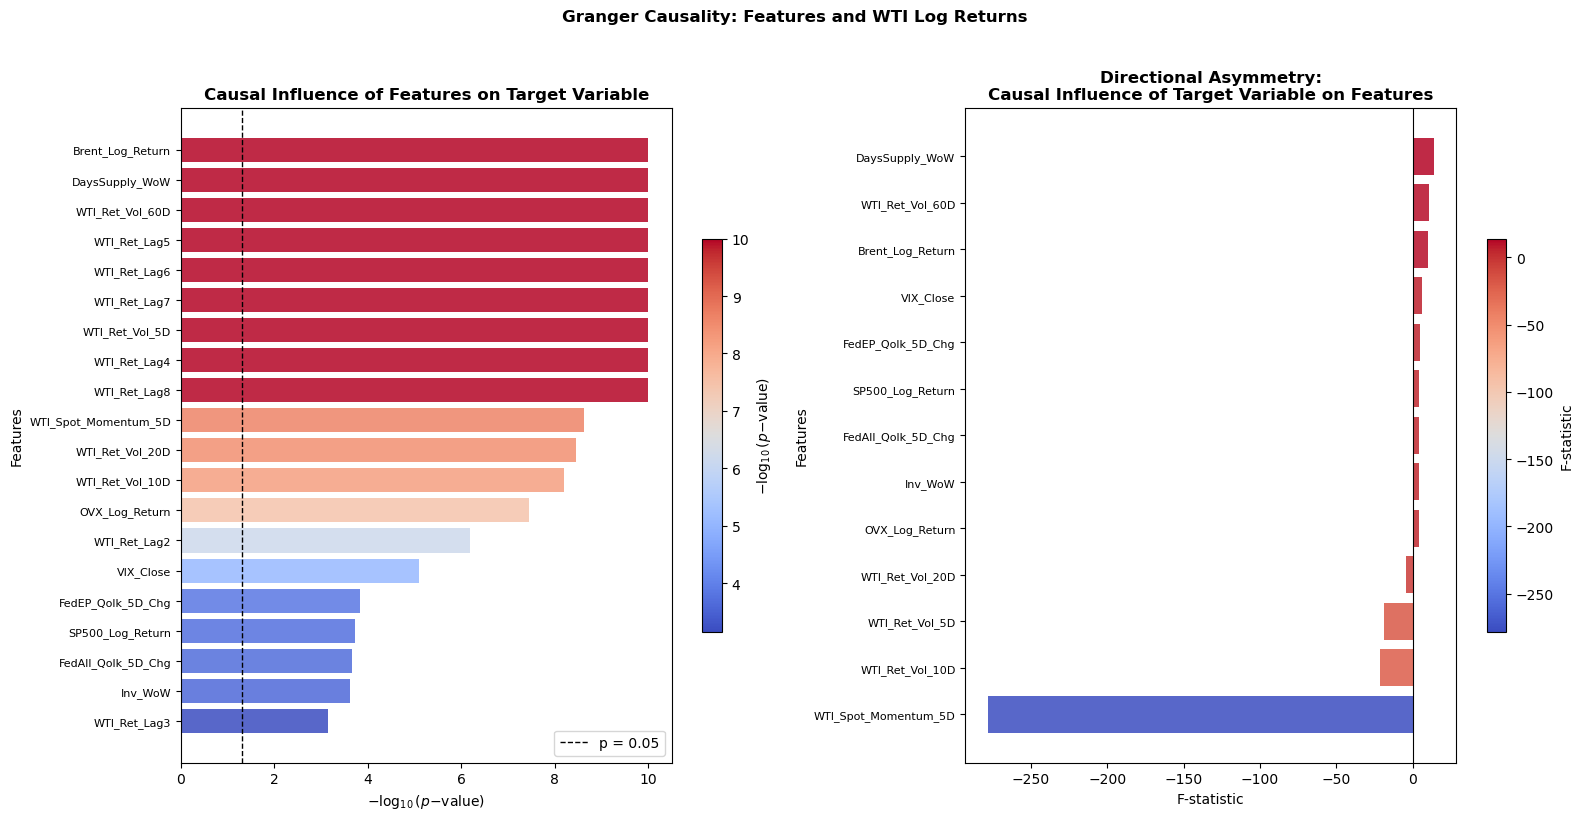

In [53]:
gc_results = run_granger_causality(
    df,
    target_col='WTI_Log_Returns', # NOTE: Not using target variable!
    feature_cols=feature_cols,
    max_lag=5)

# print(gc_results[gc_results['significant']].to_string())
plot_granger_results(gc_results, title='Granger Causality: Features and WTI Log Returns', figname='GrangerCausality')

In [54]:
print(gc_results[['feature', 'f_statistic', 'rev_f_statistic', 'gc_asymmetry']]
      .sort_values('gc_asymmetry').head(10).to_string())

                 feature  f_statistic  rev_f_statistic  gc_asymmetry
2           WTI_Ret_Lag1     4.063214     5.364800e+07 -5.364800e+07
3           WTI_Ret_Lag2    14.334681     2.685995e+06 -2.685981e+06
4           WTI_Ret_Lag3     5.690914     5.519688e+05 -5.519631e+05
5           WTI_Ret_Lag4    12.503407     5.289270e+05 -5.289145e+05
6           WTI_Ret_Lag5    13.264431     4.028587e+05 -4.028454e+05
16  WTI_Spot_Momentum_5D     9.892999     2.883006e+02 -2.784076e+02
13       WTI_Ret_Vol_10D     9.454017     3.061542e+01 -2.116141e+01
12        WTI_Ret_Vol_5D    12.844248     3.121281e+01 -1.836856e+01
11         WTI_Ret_Lag10     2.096421     1.382601e+01 -1.172959e+01
25        DXY_Log_Return     0.789757     7.226870e+00 -6.437113e+00


#### Transfer Entropy

In [55]:
def transfer_entropy(x, y, k=1, l=1, bins=n_bins_full):

    ## Properly align past, present, and future
    offset = max(k, l)
    y_future = y[offset:]
    y_past = y[offset - k: len(y) - k]
    x_past = x[offset - l: len(x) - l]

    ## Trim to equal length
    n = min(len(y_future), len(y_past), len(x_past))
    y_future = y_future[:n]
    y_past = y_past[:n]
    x_past = x_past[:n]
    
    y_future = np.asarray(y_future, dtype=float)
    y_past = np.asarray(y_past,   dtype=float)
    x_past = np.asarray(x_past,   dtype=float)

    def joint_entropy_2d(a, b, bins):
        a = np.asarray(a, dtype=float).flatten()
        b = np.asarray(b, dtype=float).flatten()
        sample = np.column_stack([a, b])
        counts, _ = np.histogramdd(sample, bins=bins)
        probs = counts / counts.sum()
        probs = probs[probs > 0]
        return -np.sum(probs * np.log(probs))


    def joint_entropy_3d(a, b, c, bins):
        a = np.asarray(a, dtype=float).flatten()
        b = np.asarray(b, dtype=float).flatten()
        c = np.asarray(c, dtype=float).flatten()
        sample = np.column_stack([a, b, c])
        counts, _ = np.histogramdd(sample, bins=bins)
        probs = counts / counts.sum()
        probs = probs[probs > 0]
        return -np.sum(probs * np.log(probs))

    ## TE = H(Y_f, Y_p) - H(Y_p) - H(Y_f, Y_p, X_p) + H(Y_p, X_p)
    h_yf_yp = joint_entropy_2d(y_future, y_past, bins)
    h_yp = entropy(y_past, bins)
    h_yf_yp_xp = joint_entropy_3d(y_future, y_past, x_past, bins)
    h_yp_xp = joint_entropy_2d(y_past, x_past, bins)

    te = h_yf_yp - h_yp - h_yf_yp_xp + h_yp_xp
    
    return max(te, 0.0) # TE is non-negative by definition; clip numerical noise

In [56]:
def permutation_test_te(x, y, k=1, l=1, bins=n_bins_full,
                         n_permutations=250, significance=0.05):
    
    observed_te = transfer_entropy(x, y, k=k, l=l, bins=bins)

    null_distribution = []
    x_shuffled = x.copy()
    
    ## Shuffle to remove autocorrelation
    for i in range(n_permutations):
        np.random.shuffle(x_shuffled)
        null_te = transfer_entropy(x_shuffled, y, k=k, l=l, bins=bins)
        null_distribution.append(null_te)

    null_distribution = np.array(null_distribution)
    p_value = (null_distribution >= observed_te).mean()
    
    return observed_te, p_value, p_value < significance

In [57]:
def run_transfer_entropy(df, target_col, feature_cols, k=1, l=1,
                         bins=n_bins_full, n_permutations=250, significance=0.05):

    results = []
    n = len(feature_cols)

    for idx, feature in enumerate(feature_cols):
        print(f'[{idx+1}/{n}] {feature}', end='\r')

        sub = df[[target_col, feature]].dropna()
        y = sub[target_col].values
        x = sub[feature].values

        ## Forward: feature -> target
        te_fwd, p_fwd, sig_fwd = permutation_test_te(x, y, k=k, l=l, bins=bins,
                                                     n_permutations=n_permutations,
                                                     significance=significance)

        ## Reverse: target -> feature (for asymmetry)
        te_rev, p_rev, sig_rev = permutation_test_te(y, x, k=k, l=l, bins=bins,
                                                     n_permutations=n_permutations,
                                                     significance=significance)

        results.append({
            'feature': feature,
            'te_forward': te_fwd,
            'p_forward': p_fwd,
            'sig_forward': sig_fwd,
            'te_reverse': te_rev,
            'p_reverse': p_rev,
            'sig_reverse': sig_rev,
            'te_asymmetry': te_fwd - te_rev, # Positive value implies feature drives WTI
        })

    return pd.DataFrame(results).sort_values('te_forward', ascending=False)

In [58]:
def plot_te_results(te_df, figname=None, title='Transfer Entropy Results', top_n=20):

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
 
    cmap = plt.cm.coolwarm
 
    plot_fwd = te_df.dropna(subset=['te_forward']).nlargest(top_n, 'te_forward').sort_values('te_forward', ascending=True)
 
    norm_fwd = plt.Normalize(vmin=plot_fwd['te_forward'].min(), vmax=plot_fwd['te_forward'].max())
    colors_fwd = cmap(norm_fwd(plot_fwd['te_forward'].values))
 
    axes[0].barh(plot_fwd['feature'], plot_fwd['te_forward'], color=colors_fwd, alpha=0.85)
    axes[0].set_xlabel('Transfer Entropy (nats)')
    axes[0].set_ylabel('Features')
    axes[0].set_title(r'Transfer Entropy from Features to Target Variable', fontweight='bold')
    axes[0].tick_params(axis='y', labelsize=8)
 
    sm0 = plt.cm.ScalarMappable(cmap=cmap, norm=norm_fwd)
    sm0.set_array([])
    plt.colorbar(sm0, ax=axes[0], label='Transfer Entropy (nats)', shrink=0.6)
 
    plot_asym = te_df.loc[plot_fwd.index].dropna(subset=['te_asymmetry']).sort_values('te_asymmetry', ascending=True)
 
    norm_asym = plt.Normalize(vmin=plot_asym['te_asymmetry'].min(), vmax=plot_asym['te_asymmetry'].max())
    colors_asym = cmap(norm_asym(plot_asym['te_asymmetry'].values))
 
    axes[1].barh(plot_asym['feature'], plot_asym['te_asymmetry'], color=colors_asym, alpha=0.85)
    axes[1].axvline(0, color='black', linewidth=0.8)
    axes[1].set_xlabel(r'Transfer Entropy (nats)')
    axes[1].set_ylabel('Features')
    axes[1].set_title('Directional Asymmetry:\n'
                      'Transfer Entropy from Target Variable to Features',
                      fontweight='bold')
    axes[1].tick_params(axis='y', labelsize=8)
    
    ## Degenerate features removed rather than using symlog scale
    # axes[0].set_xscale('symlog', linthresh=0.025)
    # axes[1].set_xscale('symlog', linthresh=0.025)
 
    sm1 = plt.cm.ScalarMappable(cmap=cmap, norm=norm_asym)
    sm1.set_array([])
    plt.colorbar(sm1, ax=axes[1], label=r'Transfer Entropy (nats)', shrink=0.6)
 
    plt.suptitle(title, fontweight='bold', y=1.02)
    plt.tight_layout()
    if figname:
        plt.savefig(f'../Figures/{figname}.pdf', bbox_inches='tight')
    plt.show()

In [59]:
def build_lag_matrix(series, lags):

    max_lag = max(lags)
    rows = []
    for lag in lags:
        rows.append(series[max_lag - lag: len(series) - lag])
    return np.column_stack(rows)


def log_det(matrix):

    eigenvalues = np.linalg.eigvalsh(matrix)
    ## Clip small negatives from numerical noise
    eigenvalues = np.clip(eigenvalues, 1e-12, None)
    return np.sum(np.log(eigenvalues))

In [60]:
def gaussian_transfer_entropy(x, y, h=1, k=1, l=1):

    x = np.asarray(x, dtype=float).flatten()
    y = np.asarray(y, dtype=float).flatten()

    max_lag = max(k, l)
    offset = max_lag + h - 1

    ## Y_future: Y_{t+h}
    y_future = y[offset:]

    ## Y_past Lags: One column per lag, then trim to align with y_future
    y_past_cols = [y[offset - lag: len(y) - lag] for lag in range(1, k + 1)]
    x_past_cols = [x[offset - lag: len(x) - lag] for lag in range(1, l + 1)]

    ## Trim all to same length
    n = min(len(y_future), *[len(c) for c in y_past_cols], *[len(c) for c in x_past_cols])

    y_future = y_future[:n]
    y_past_cols = [c[:n] for c in y_past_cols]
    x_past_cols = [c[:n] for c in x_past_cols]

    y_past = np.column_stack(y_past_cols)
    x_past = np.column_stack(x_past_cols)

    yf_yp = np.column_stack([y_future, y_past])
    xp_yp = np.column_stack([x_past,   y_past])
    yf_xp_yp = np.column_stack([y_future, x_past, y_past])

    ## Covariance matrices
    cov_yf_yp = np.cov(yf_yp.T)
    cov_xp_yp = np.cov(xp_yp.T)
    cov_yf_xp_yp = np.cov(yf_xp_yp.T)
    cov_yp = np.cov(y_past.T) if k > 1 else np.atleast_2d(np.var(y_past))

    ## Equation 10.20 from textbook
    log_num = log_det(cov_yf_yp) + log_det(cov_xp_yp)
    log_den = log_det(cov_yf_xp_yp) + log_det(cov_yp)
    te = 0.5 * (log_num - log_den)
    
    return max(te, 0.0) # Trim TE again, per its definition

In [61]:
def run_gaussian_transfer_entropy(df, target_col, feature_cols,
                                   h=1, k=1, l=1):
    results = []
    n = len(feature_cols)

    for idx, feature in enumerate(feature_cols):
        print(f'[{idx+1}/{n}] {feature}', end='\r')

        sub = df[[target_col, feature]].dropna()
        y = sub[target_col].values
        x = sub[feature].values

        te_fwd = gaussian_transfer_entropy(x, y, h=h, k=k, l=l)
        te_rev = gaussian_transfer_entropy(y, x, h=h, k=k, l=l)

        results.append({
            'feature': feature,
            'te_forward': te_fwd,
            'te_reverse': te_rev,
            'te_asymmetry': te_fwd - te_rev,
            'sig_forward': None,
            'sig_reverse': None,
        })

    return pd.DataFrame(results).sort_values('te_forward', ascending=False)

In [62]:
def plot_gaussian_te_results(te_df, figname=None,
                             title='Gaussian Transfer Entropy Results',
                             top_n=20):

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
 
    cmap = plt.cm.coolwarm

    plot_fwd = te_df.dropna(subset=['te_forward']).nlargest(top_n, 'te_forward').sort_values('te_forward', ascending=True)
 
    norm_fwd = plt.Normalize(vmin=plot_fwd['te_forward'].min(), vmax=plot_fwd['te_forward'].max())
    colors_fwd = cmap(norm_fwd(plot_fwd['te_forward'].values))
 
    axes[0].barh(plot_fwd['feature'], plot_fwd['te_forward'], color=colors_fwd, alpha=0.85)
    axes[0].set_xlabel('Transfer Entropy (nats)')
    axes[0].set_ylabel('Features')
    axes[0].set_title('Transfer Entropy from Features to Target Variable', fontweight='bold')
    axes[0].tick_params(axis='y', labelsize=8)
 
    sm0 = plt.cm.ScalarMappable(cmap=cmap, norm=norm_fwd)
    sm0.set_array([])
    plt.colorbar(sm0, ax=axes[0], label='Transfer Entropy (nats)', shrink=0.6)
 
    plot_asym = te_df.loc[plot_fwd.index].dropna(subset=['te_asymmetry']).sort_values('te_asymmetry', ascending=True)
 
    norm_asym = plt.Normalize(vmin=plot_asym['te_asymmetry'].min(), vmax=plot_asym['te_asymmetry'].max())
    colors_asym = cmap(norm_asym(plot_asym['te_asymmetry'].values))
 
    axes[1].barh(plot_asym['feature'], plot_asym['te_asymmetry'], color=colors_asym, alpha=0.85)
    axes[1].axvline(0, color='black', linewidth=0.8)
    axes[1].set_xlabel(r'Transfer Entropy (nats)')
    axes[1].set_ylabel('Features')
    axes[1].set_title('Directional Asymmetry:\n'
                      'Transfer Entropy from Target Variable to Features',
                      fontweight='bold')
    axes[1].tick_params(axis='y', labelsize=8)
    
    ## Like before, do not use symlog scale
    # axes[0].set_xscale('symlog', linthresh=0.025)
    # axes[1].set_xscale('symlog', linthresh=0.025)
 
    sm1 = plt.cm.ScalarMappable(cmap=cmap, norm=norm_asym)
    sm1.set_array([])
    plt.colorbar(sm1, ax=axes[1], label=r'Transfer Entropy (nats)', shrink=0.6)
 
    plt.suptitle(title, fontweight='bold', y=1.02)
    plt.tight_layout()
    if figname:
        plt.savefig(f'../Figures/{figname}.pdf', bbox_inches='tight')
    plt.show()

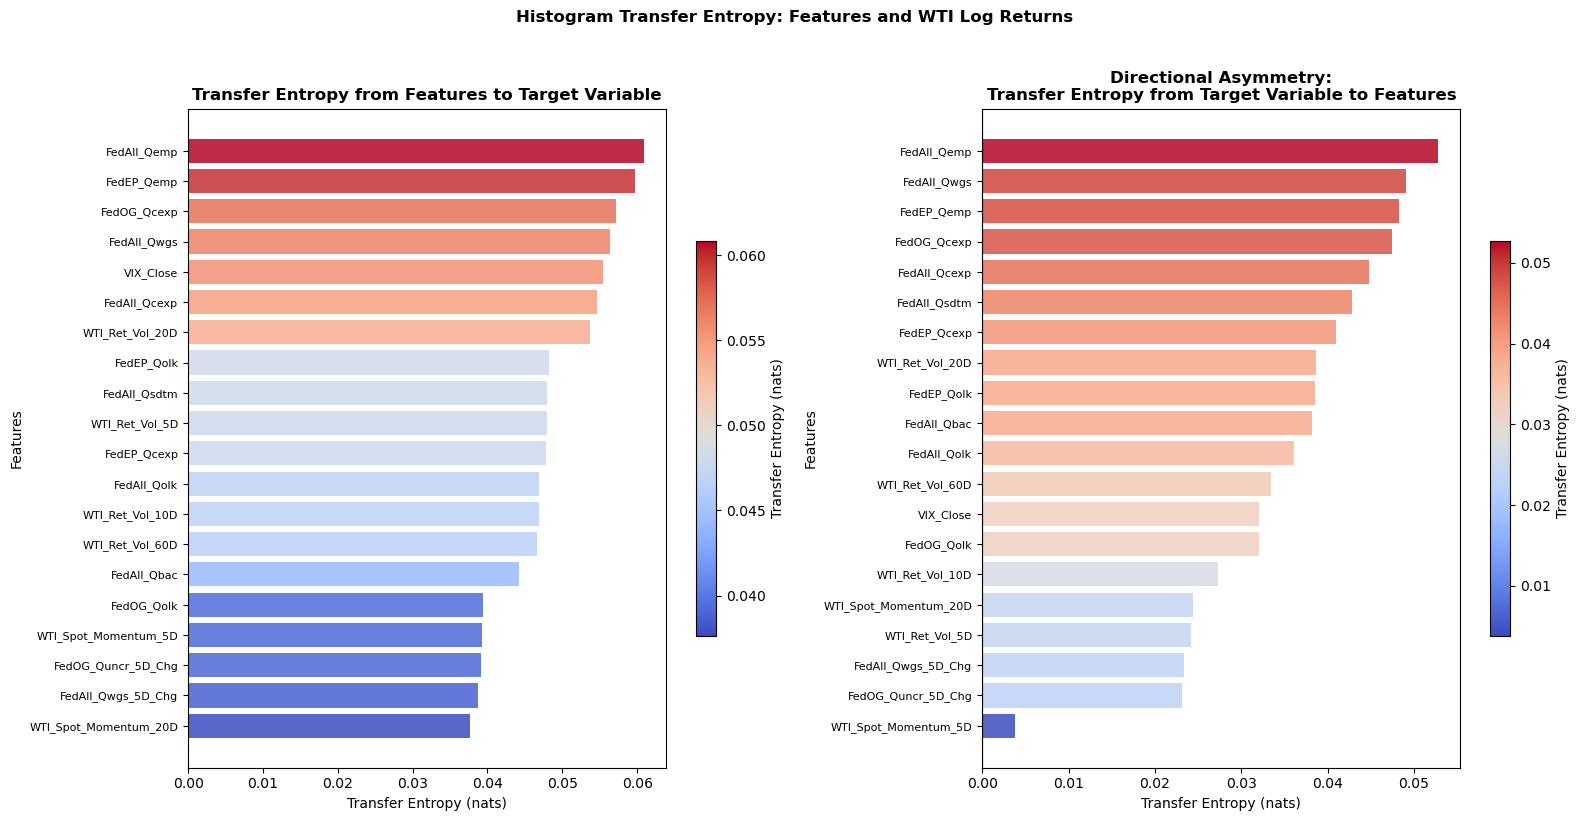

In [63]:
te_results = run_transfer_entropy(df, target_col='WTI_Log_Returns', feature_cols=feature_cols,
                                  k=1, l=1, bins=n_bins_full, n_permutations=250)

# print(te_results[te_results['sig_forward']].to_string())
plot_te_results(te_results, title='Histogram Transfer Entropy: Features and WTI Log Returns', figname='TransferEntropy')

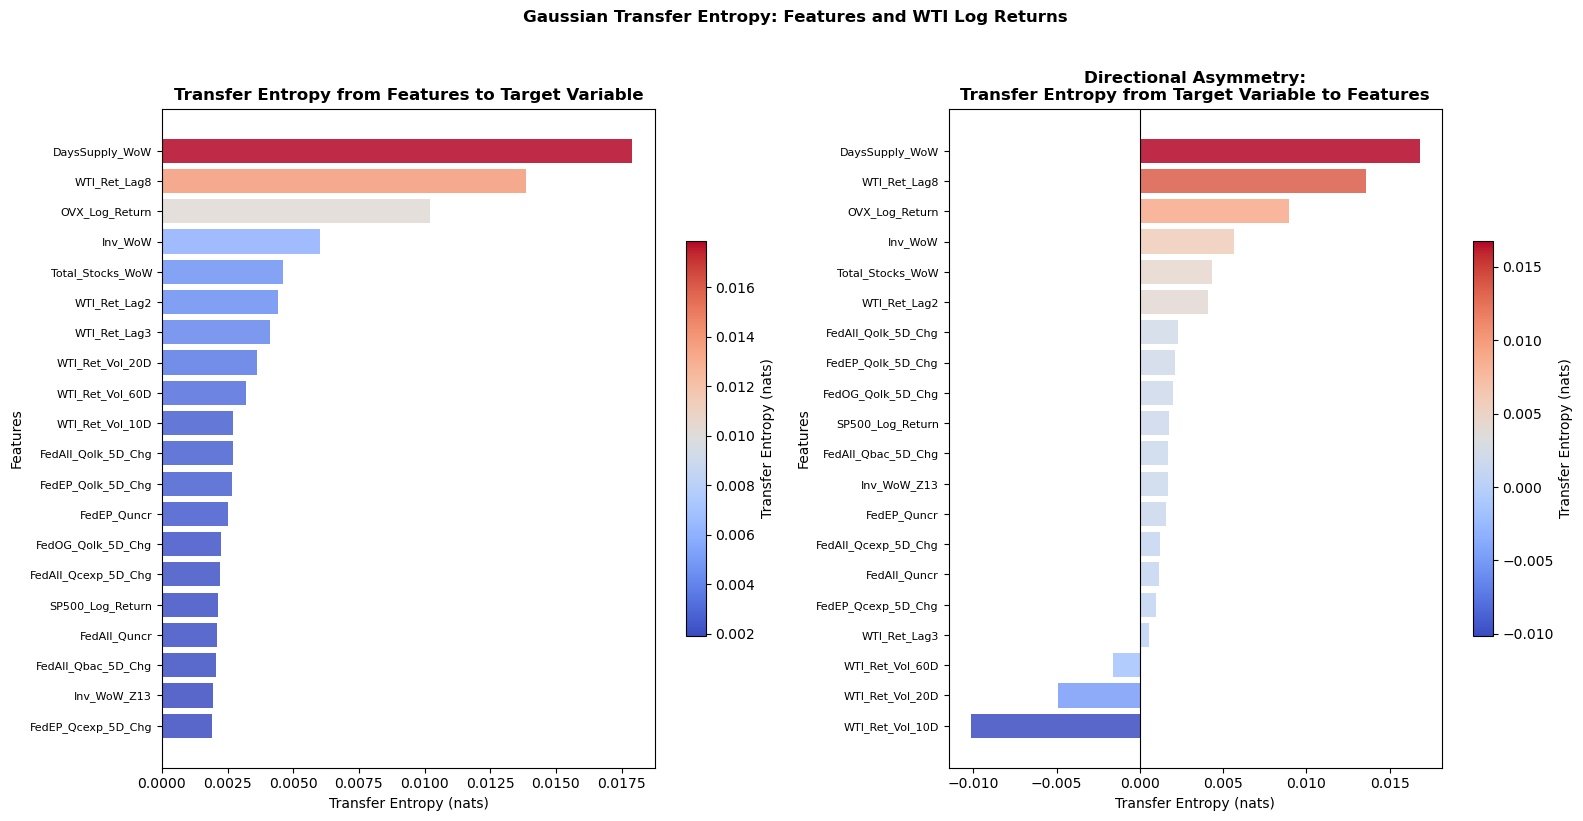

In [64]:
te_gauss_results = run_gaussian_transfer_entropy(df, target_col='WTI_Log_Returns', 
                                                 feature_cols=feature_cols, h=1, k=1, l=1)

# print(te_gauss_results[['feature', 'te_forward', 'te_reverse', 'te_asymmetry']].head(20).to_string())
te_gauss_plot = te_gauss_results[te_gauss_results['feature'] != 'WTI_Ret_Lag1']
plot_gaussian_te_results(te_gauss_plot, title='Gaussian Transfer Entropy: Features and WTI Log Returns', 
                         figname='GaussianTransferEntropy')

### Additional Diagnostics

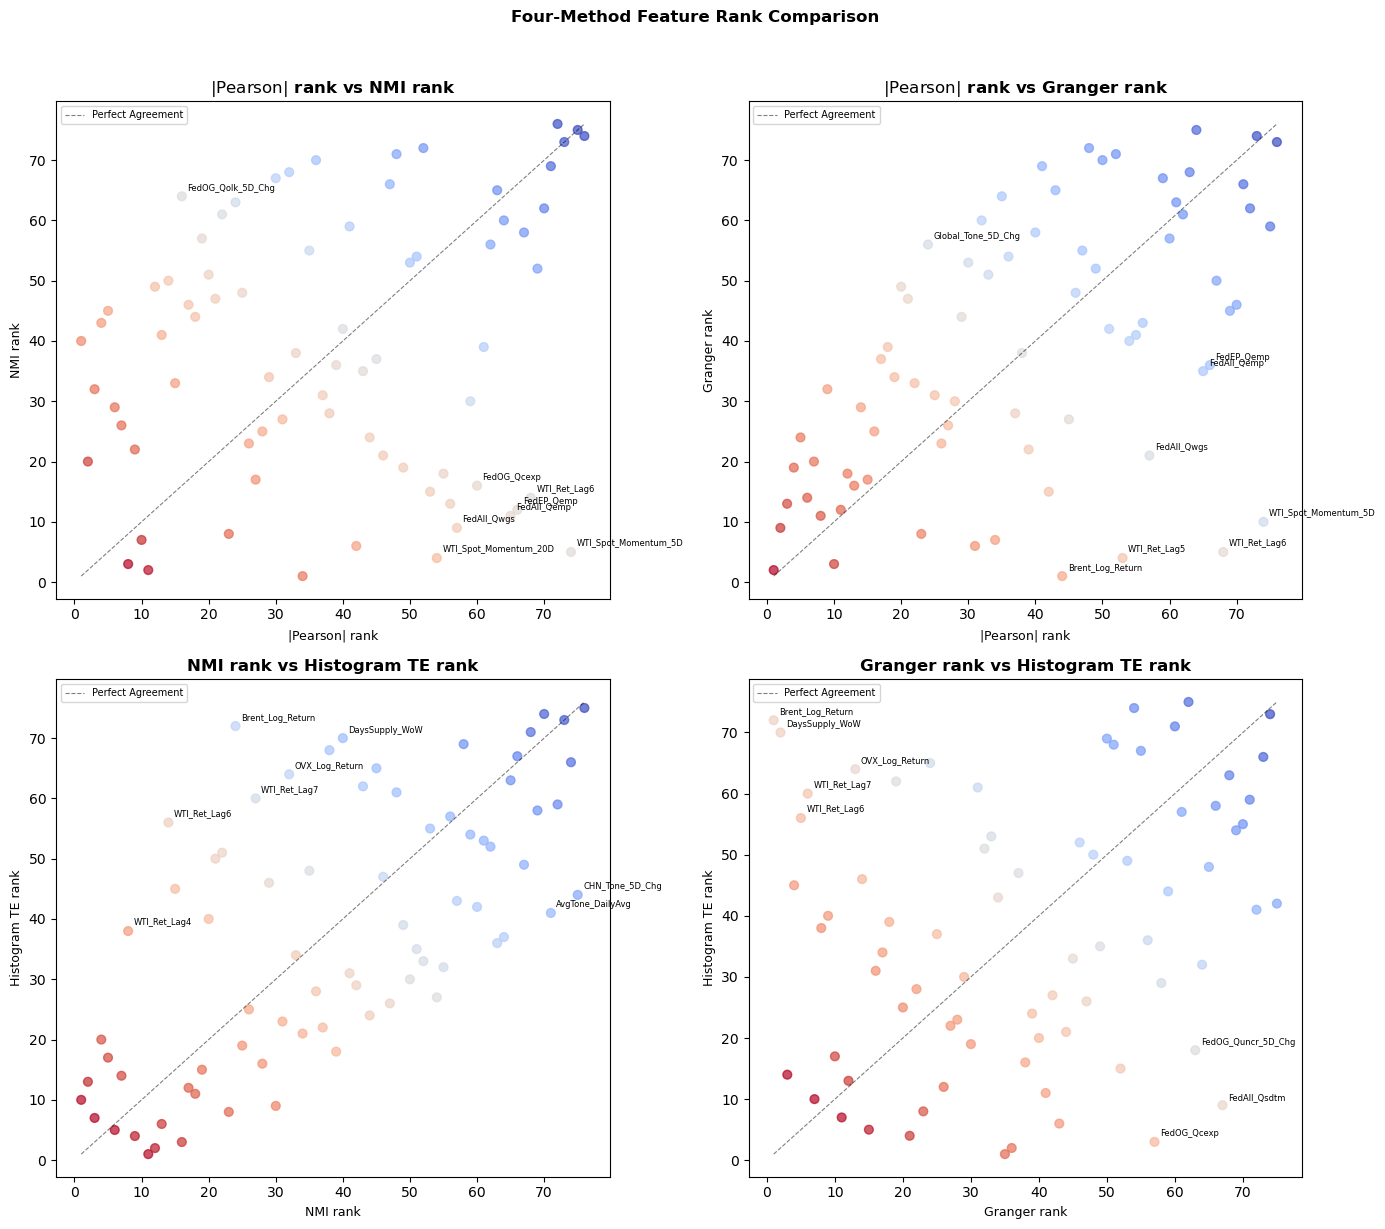

In [65]:
gc_rank_series = gc_results.set_index('feature')['p_value'].rank(ascending=True)

te_rank_series = te_results.set_index('feature')['te_forward'].rank(ascending=False)

rank_df = comparison[['pearson_rank', 'nmi_rank']].copy()
rank_df['granger_rank'] = gc_rank_series
rank_df['te_rank'] = te_rank_series
rank_df = rank_df.dropna()

pairs = [('pearson_rank', 'nmi_rank', r'$|\mathrm{Pearson}|$ rank', 'NMI rank'),
         ('pearson_rank', 'granger_rank', r'$|\mathrm{Pearson}|$ rank', 'Granger rank'),
         ('nmi_rank', 'te_rank', 'NMI rank', 'Histogram TE rank'),
         ('granger_rank', 'te_rank', 'Granger rank', 'Histogram TE rank')]

cmap = plt.cm.coolwarm
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (x_col, y_col, x_label, y_label) in zip(axes.flatten(), pairs):

    avg_rank = (rank_df[x_col].rank() + rank_df[y_col].rank()) / 2
    norm = plt.Normalize(vmin=avg_rank.min(), vmax=avg_rank.max())
    colors = cmap(1 - norm(avg_rank.values))

    ax.scatter(rank_df[x_col], rank_df[y_col], color=colors, alpha=0.7, s=40)
    ax.set_xlabel(x_label, fontsize=9)
    ax.set_ylabel(y_label, fontsize=9)
    ax.set_title(f'{x_label} vs {y_label}', fontweight='bold')

    ## Annotate features with the largest rank divergence
    divergence = (rank_df[x_col] - rank_df[y_col]).abs()
    for feat, row in rank_df.loc[divergence.nlargest(8).index].iterrows():
        ax.annotate(feat, (row[x_col], row[y_col]), fontsize=6, xytext=(4, 4), textcoords='offset points')

    ## Diagonal reference line (perfect agreement)
    lims = [1, rank_df[[x_col, y_col]].max().max()]
    ax.plot(lims, lims, 'k--', linewidth=0.8, alpha=0.5, label='Perfect Agreement')
    ax.legend(fontsize=7)

plt.suptitle('Four-Method Feature Rank Comparison', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../Figures/RankComparison_Scatter.pdf', bbox_inches='tight')
plt.show()

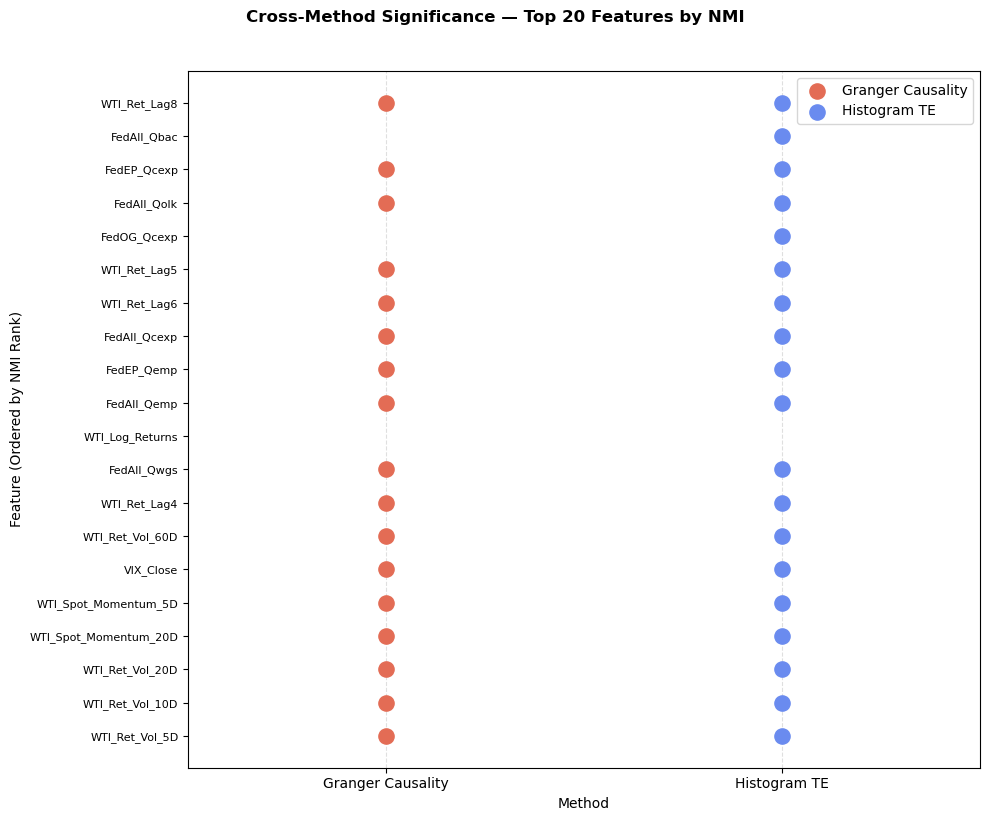

In [66]:
## For top N features by NMI, flag significance across methods
top_n_consensus = 20

top_by_nmi = nmi_target_series.head(top_n_consensus).index.tolist()

gc_sig = gc_results.set_index('feature')['significant']
te_sig = te_results.set_index('feature')['sig_forward']

consensus = pd.DataFrame({
    'NMI rank': nmi_target_series.rank(ascending=False).astype(int),
    'Pearson rank': comparison['pearson_rank'].astype(int),
    'Granger sig': gc_sig.reindex(nmi_target_series.index).fillna(False),
    'Histogram TE sig': te_sig.reindex(nmi_target_series.index).fillna(False),
}, index=nmi_target_series.index).loc[top_by_nmi]

## Count methods agreeing for each feature
consensus['n_sig'] = consensus['Granger sig'].astype(int) + consensus['Histogram TE sig'].astype(int)

methods = ['Granger sig', 'Histogram TE sig']
method_labels = ['Granger Causality', 'Histogram TE']
colors_methods = [plt.cm.coolwarm(0.85), plt.cm.coolwarm(0.15)]

fig, ax = plt.subplots(figsize=(10, 8))
y = np.arange(len(top_by_nmi))

for i, (col, label, color) in enumerate(zip(methods, method_labels, colors_methods)):
    sig_mask = consensus[col].values
    ax.scatter(np.full(sig_mask.sum(), i + 1), y[sig_mask], color=color, s=120, label=label, zorder=3)

ax.set_yticks(y)
ax.set_yticklabels(top_by_nmi, fontsize=8)
ax.set_xticks([1, 2])
ax.set_xticklabels(method_labels)
ax.set_xlim(0.5, 2.5)
ax.set_xlabel('Method')
ax.set_ylabel('Feature (Ordered by NMI Rank)')
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.legend()

plt.suptitle(f'Cross-Method Significance — Top {top_n_consensus} Features by NMI', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../Figures/CrossMethod_Consensus.pdf', bbox_inches='tight')
plt.show()

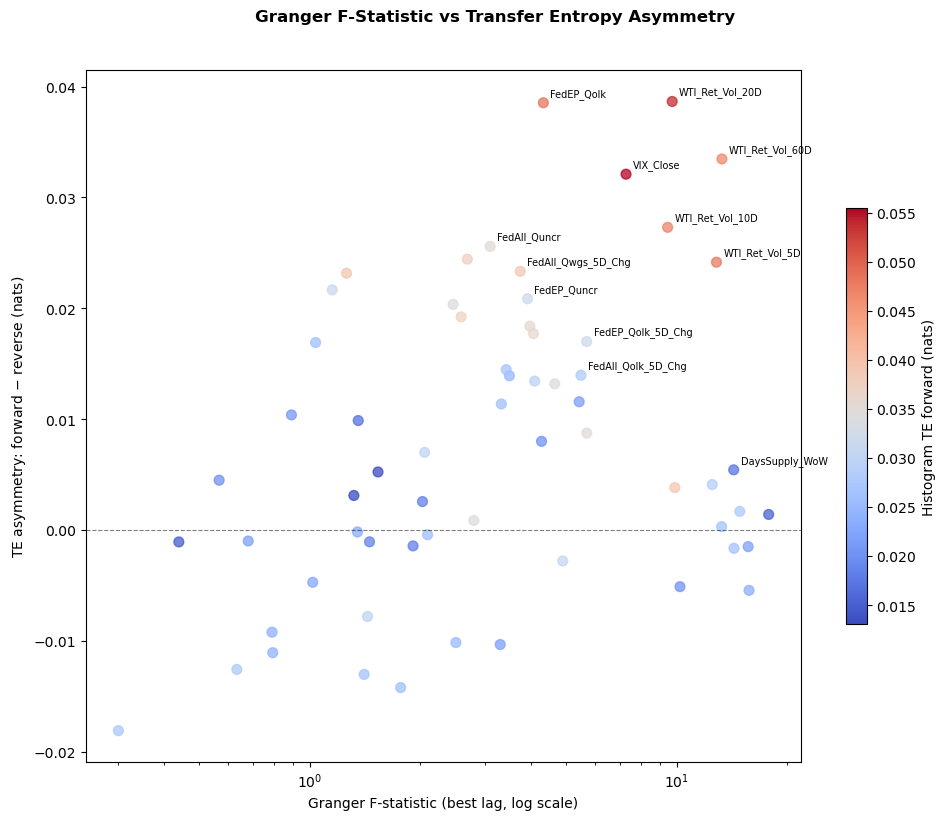

In [67]:
## Merge GC and TE results on feature
gc_plot = gc_results.set_index('feature')[['f_statistic', 'significant', 'feat_stationary']]
te_plot = te_results.set_index('feature')[['te_asymmetry', 'te_forward', 'sig_forward']]

merged = gc_plot.join(te_plot, how='inner').dropna()
merged = merged[merged['feat_stationary']]
merged = merged[merged.index != 'WTI_Ret_Lag1']

cmap = plt.cm.coolwarm
norm = plt.Normalize(vmin=merged['te_forward'].min(), vmax=merged['te_forward'].max())
colors = cmap(norm(merged['te_forward'].values))

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(merged['f_statistic'], merged['te_asymmetry'], color=colors, alpha=0.75, s=50)

## Annotate by joint ranking
joint_rank = (merged['f_statistic'].rank(ascending=False) + merged['te_asymmetry'].rank(ascending=False)) / 2
for feat, row in merged.loc[joint_rank.nsmallest(12).index].iterrows():
    ax.annotate(feat, (row['f_statistic'], row['te_asymmetry']), fontsize=7, xytext=(5, 5), textcoords='offset points')

ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
ax.set_xscale('log')
ax.set_xlabel('Granger F-statistic (best lag, log scale)')
ax.set_ylabel(r'TE asymmetry: forward $-$ reverse (nats)')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=ax, label='Histogram TE forward (nats)', shrink=0.6)

plt.suptitle('Granger F-Statistic vs Transfer Entropy Asymmetry', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../Figures/GC_vs_TE_Asymmetry.pdf', bbox_inches='tight')
plt.show()